In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
from skimage import io
import skimage.filters
from skimage.transform import resize
from PIL import Image
import cv2
from PIL import Image

import shutil

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, cohen_kappa_score
from skimage.feature import hog

# Reduce dimensions using PCA
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import GridSearchCV
!pip install scikeras
from scikeras.wrappers import KerasClassifier

from google.colab import drive, files
drive.mount('/content/drive') # mount your google colab file

tf.random.set_seed(
    42
)

%matplotlib inline

Mounted at /content/drive


# Colour images

In [ ]:
def augment(image):
  image = tf.image.random_brightness(image, max_delta=0.5)
  image = tf.image.random_contrast(image, lower=0.5, upper=1.5)
  image = tf.image.random_saturation(image, lower=0.5, upper=1.5)
  image = tf.image.random_flip_left_right(image)
  return image

SIZE = 128  #Resize images

#Capture training data and labels into respective lists
images = []
labels = []

#Folder to put images that has weird sizes.
data_error_dir = "/content/drive/MyDrive/ML_IPData7/imgerrors"
! mkdir $data_error_dir
data_errsizesushi_dir = "/content/drive/MyDrive/ML_IPData7/imgsizeerrors"
! mkdir $data_errsizesushi_dir
data_errsizesword_dir = "/content/drive/MyDrive/ML_IPData7/imgsizeerrorssword"
! mkdir $data_errsizesword_dir

for directory_path in glob.glob("/content/drive/MyDrive/ML_IPData7/Datasets/*"):
    label = directory_path.split("/")[-1]
    print(label)
    for img_path in glob.glob(os.path.join(directory_path, "*.jpg")):
        img = io.imread(img_path)

        # Move all images with weird sizes to another folder
        if (len(img.shape) < 3):
          shutil.move(img_path, data_error_dir)
          print(img.shape)
          continue
        # Move all images with weird sizes to another folder
        elif img.shape[0] < 128 or img.shape[1] < 128:
          shutil.move(img_path, data_errsizesword_dir)
          continue
        else:
          img = resize(img, (SIZE, SIZE, 3))

        labels.append(label)
        images.append(img)

        if label == "Sword":
          for i in range(0,3):
            img = augment(img)
            images.append(img)
            labels.append(label)

img = []

mkdir: cannot create directory ‘/content/drive/MyDrive/ML_IPData7/imgerrors’: File exists
mkdir: cannot create directory ‘/content/drive/MyDrive/ML_IPData7/imgsizeerrors’: File exists
mkdir: cannot create directory ‘/content/drive/MyDrive/ML_IPData7/imgsizeerrorssword’: File exists
Sushi
Sword


In [ ]:
images = np.array(images)
labels = np.array(labels)
type(labels)
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
labelencoder = LabelEncoder()

labelencoder.fit(labels)
enc_labels = labelencoder.transform(labels)

print(enc_labels[0])
print(labels[0])

0
Sushi


In [ ]:
flattened_images = []

for img in images:
  img = img.reshape((img.shape[0] * img.shape[1] * img.shape[2]))
  flattened_images.append(img)

images = []
labels = []

flattened_images = np.array(flattened_images)
print(flattened_images.shape)

X_train, X_test, y_train, y_test = train_test_split (flattened_images, enc_labels, test_size = 0.2, random_state = 1)


# Your code to Print the shapes of the X_train, X_test, y_train, y_test

print (X_train.shape)
print (X_test.shape)
print (y_train.shape)
print (y_test.shape)


(3007, 49152)
(2405, 49152)
(602, 49152)
(2405,)
(602,)


Text(0, 0.5, 'Cumulated variance')

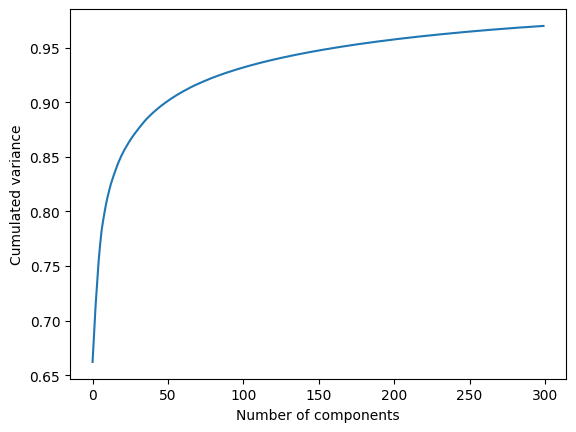

In [ ]:
# data is centered by PCA

# How many components to choose?
pca_tr = PCA(n_components=300)
# Why apply PCA to the training data and not to all data?
pca_tr.fit(X_train)
plt.plot(np.cumsum(pca_tr.explained_variance_ratio_))
plt.xlabel("Number of components")
plt.ylabel("Cumulated variance")

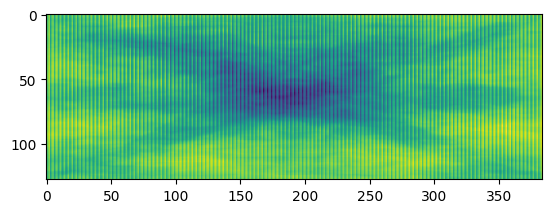

In [ ]:
test = pca_tr.components_[0].reshape(SIZE, SIZE*3)
plt.imshow(test)
test = []

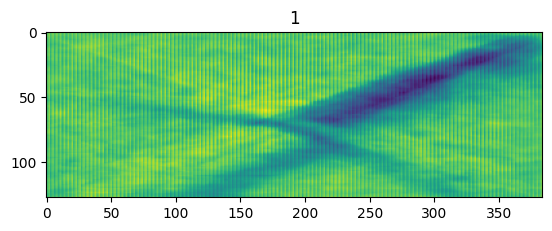

In [ ]:
# Reconstruct one image from the first 300 bases
projims = pca_tr.transform(X_test)
k = 10
res = np.zeros((SIZE*SIZE*3))
for i in range(300):
  res += pca_tr.components_[i].dot(projims[k,i])

plt.imshow(res.reshape(SIZE, SIZE*3))
plt.title(y_test[k])

projims = []
res = []

## KNN with PCA

              precision    recall  f1-score   support

           0       0.94      0.68      0.79       304
           1       0.75      0.96      0.84       298

    accuracy                           0.82       602
   macro avg       0.84      0.82      0.82       602
weighted avg       0.85      0.82      0.82       602

Train score: 0.837838
Test score: 0.818937
Kappa score: 0.638830


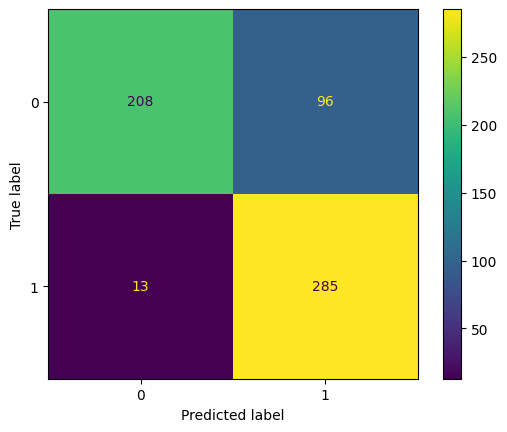

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here?
knn = KNeighborsClassifier(n_neighbors = 7)
knn.fit(pca_tr.transform(X_train), y_train)

y_pred = knn.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

knn_orig_score_pca = knn.score(pca_tr.transform(X_test), y_test)

print("Train score: %f" % knn.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % knn.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
grid_params = { 'n_neighbors' : [5,7,9,11,13,15],
               'weights' : ['uniform','distance'],
               'metric' : ['minkowski','euclidean','manhattan']}

gs = GridSearchCV(KNeighborsClassifier(), grid_params, verbose = 1, cv=3, n_jobs = -1)

g_res = gs.fit(pca_tr.transform(X_train), y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
0.8116496108874713
{'metric': 'minkowski', 'n_neighbors': 7, 'weights': 'distance'}


              precision    recall  f1-score   support

           0       0.95      0.68      0.79       304
           1       0.75      0.96      0.84       298

    accuracy                           0.82       602
   macro avg       0.85      0.82      0.82       602
weighted avg       0.85      0.82      0.82       602

Train score: 1.000000
Test score: 0.820598
Kappa score: 0.642156


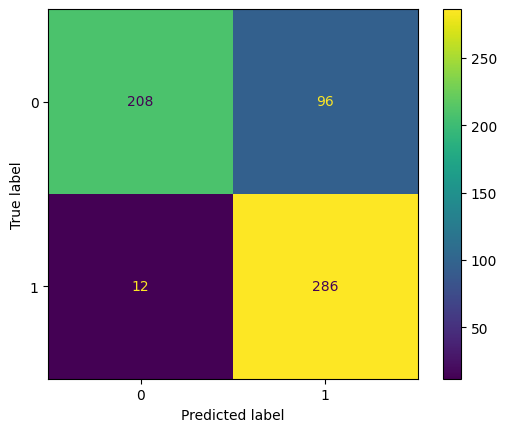

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here?
knn = KNeighborsClassifier(metric = 'minkowski', n_neighbors = 7, weights = 'distance')
knn.fit(pca_tr.transform(X_train), y_train)

y_pred = knn.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

knn_mod_score_pca = knn.score(pca_tr.transform(X_test), y_test)

print("Train score: %f" % knn.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % knn.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## KNN without PCA

              precision    recall  f1-score   support

           0       0.96      0.61      0.75       304
           1       0.71      0.97      0.82       298

    accuracy                           0.79       602
   macro avg       0.83      0.79      0.78       602
weighted avg       0.84      0.79      0.78       602

Train score: 0.808316
Test score: 0.790698
Kappa score: 0.582873


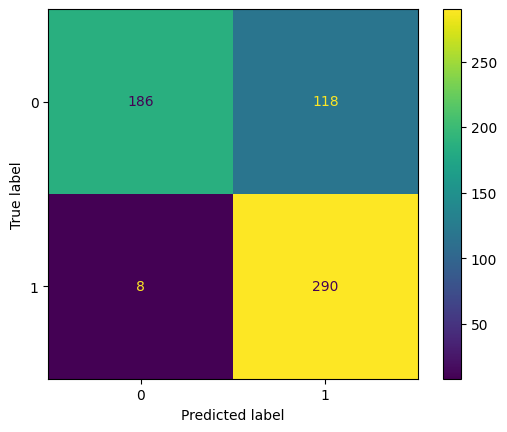

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here?
knn = KNeighborsClassifier(n_neighbors = 7)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

knn_orig_score_nopca = knn.score(X_test, y_test)

print("Train score: %f" % knn.score(X_train, y_train))
print("Test score: %f" % knn.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
grid_params = { 'n_neighbors' : [5,7,9,11,13,15],
               'weights' : ['uniform','distance'],
               'metric' : ['minkowski','euclidean','manhattan']}

gs = GridSearchCV(KNeighborsClassifier(), grid_params, verbose = 1, cv=3, n_jobs = -1)

g_res = gs.fit(X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
0.8474039620050996
{'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}


              precision    recall  f1-score   support

           0       0.94      0.78      0.85       304
           1       0.81      0.95      0.87       298

    accuracy                           0.86       602
   macro avg       0.88      0.86      0.86       602
weighted avg       0.88      0.86      0.86       602

Train score: 1.000000
Test score: 0.863787
Kappa score: 0.728034


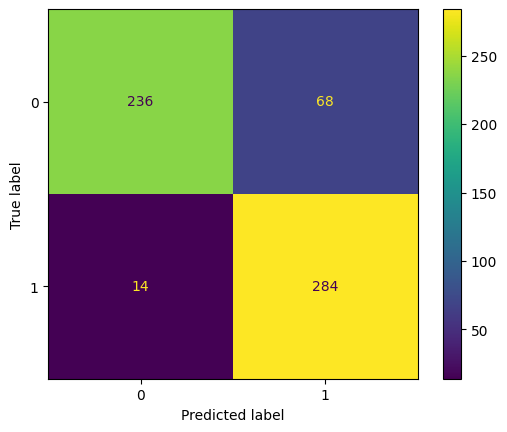

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here?
knn = KNeighborsClassifier(metric = 'manhattan', n_neighbors = 5, weights = 'distance')
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

knn_mod_score_nopca = knn.score(X_test, y_test)

print("Train score: %f" % knn.score(X_train, y_train))
print("Test score: %f" % knn.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## Decision tree with PCA

In [ ]:
# Terrible decision tree classifier - directly on pixel values
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import ExtraTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

dt = DecisionTreeClassifier(criterion='gini')
dt = dt.fit(pca_tr.transform(X_train), y_train)
y_pred = dt.predict(pca_tr.transform(X_test))
report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % dt.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % dt.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
grid_params = { 'n_neighbors' : [5,7,9,11,13,15],
               'weights' : ['uniform','distance'],
               'metric' : ['minkowski','euclidean','manhattan']}

gs = GridSearchCV(DecisionTreeClassifier(), grid_params, verbose = 1, cv=3, n_jobs = -1)

g_res = gs.fit(X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

              precision    recall  f1-score   support

           0       0.86      0.88      0.87       304
           1       0.87      0.86      0.86       298

    accuracy                           0.87       602
   macro avg       0.87      0.87      0.87       602
weighted avg       0.87      0.87      0.87       602

Train score: 1.000000
Test score: 0.865449


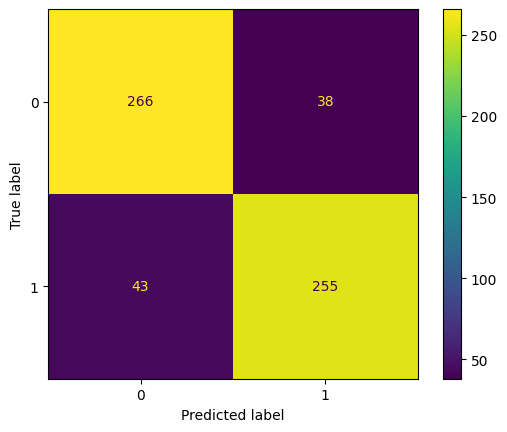

In [ ]:
# Terrible decision tree classifier - directly on pixel values
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import ExtraTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

dt = DecisionTreeClassifier(criterion='gini')
dt = dt.fit(pca_tr.transform(X_train), y_train)
y_pred = dt.predict(pca_tr.transform(X_test))
report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % dt.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % dt.score(pca_tr.transform(X_test), y_test))

## Decision tree without PCA

              precision    recall  f1-score   support

           0       0.85      0.85      0.85       304
           1       0.85      0.85      0.85       298

    accuracy                           0.85       602
   macro avg       0.85      0.85      0.85       602
weighted avg       0.85      0.85      0.85       602

Train score: 1.000000
Test score: 0.848837


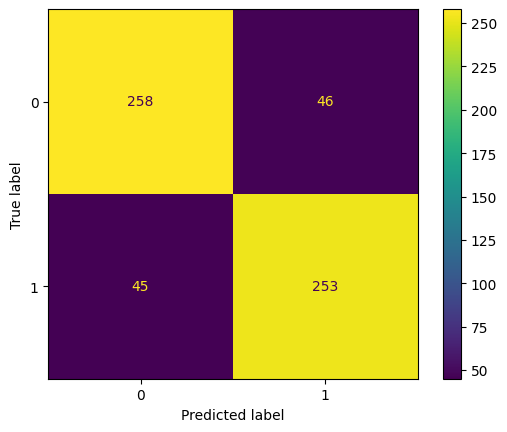

In [ ]:
# Terrible decision tree classifier - directly on pixel values
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import ExtraTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

dt = DecisionTreeClassifier(criterion='gini')
dt = dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)
report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % dt.score(X_train, y_train))
print("Test score: %f" % dt.score(X_test, y_test))

## Random forest with PCA

              precision    recall  f1-score   support

           0       0.87      0.95      0.91       304
           1       0.94      0.86      0.90       298

    accuracy                           0.90       602
   macro avg       0.91      0.90      0.90       602
weighted avg       0.91      0.90      0.90       602

Train score: 0.981705
Test score: 0.901993
Kappa score: 0.803792


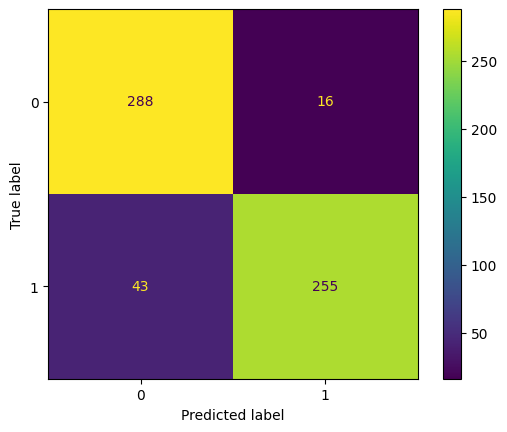

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(max_depth=7, random_state=0)

# Random forest classifier - directly on pixel values
RF = RF.fit(pca_tr.transform(X_train), y_train)

y_pred = RF.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

rf_orig_score_pca = RF.score(pca_tr.transform(X_test), y_test)

print("Train score: %f" % RF.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % RF.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
from sklearn.ensemble import RandomForestClassifier

grid_params = {
    'max_features': ['sqrt', 'log2'],
    'n_estimators': [100, 200, 300, 500],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [5, 8, 10],
    'random_state': [0],
    'n_jobs' : [-1]
}

gs = GridSearchCV(RandomForestClassifier(), grid_params, verbose = 1, cv=3, n_jobs = -1)

g_res = gs.fit(pca_tr.transform(X_train), y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 3 folds for each of 72 candidates, totalling 216 fits


/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


0.929315288557632
{'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 500, 'n_jobs': -1, 'random_state': 0}


              precision    recall  f1-score   support

           0       0.90      0.96      0.93       304
           1       0.95      0.89      0.92       298

    accuracy                           0.92       602
   macro avg       0.92      0.92      0.92       602
weighted avg       0.92      0.92      0.92       602

Train score: 0.996674
Test score: 0.921927
Kappa score: 0.843730


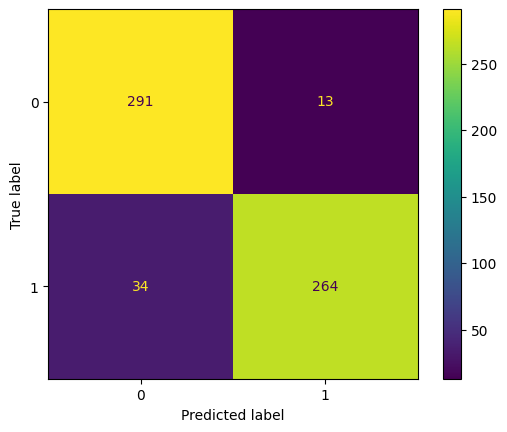

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(max_depth = 10, random_state = 0, n_estimators = 500, n_jobs = -1)

# Random forest classifier - directly on pixel values
RF = RF.fit(pca_tr.transform(X_train), y_train)

y_pred = RF.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

rf_mod_score_pca = RF.score(pca_tr.transform(X_test), y_test)

print("Train score: %f" % RF.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % RF.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## Random forest without PCA

              precision    recall  f1-score   support

           0       0.91      0.96      0.93       304
           1       0.96      0.90      0.93       298

    accuracy                           0.93       602
   macro avg       0.93      0.93      0.93       602
weighted avg       0.93      0.93      0.93       602

Train score: 0.980457
Test score: 0.931894
Kappa score: 0.863697


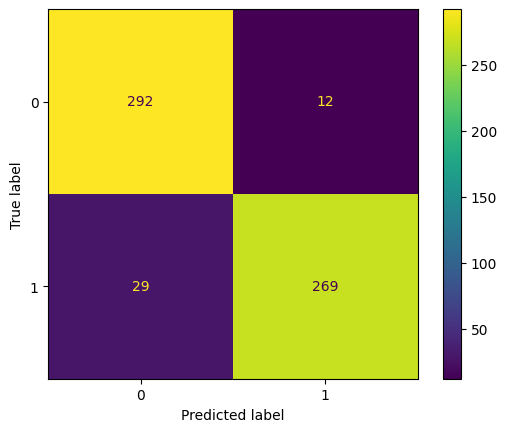

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(max_depth=7, random_state=0)

# Random forest classifier - directly on pixel values
RF = RF.fit(X_train, y_train)

y_pred = RF.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

rf_orig_score_nopca = RF.score(X_test, y_test)

print("Train score: %f" % RF.score(X_train, y_train))
print("Test score: %f" % RF.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
from sklearn.ensemble import RandomForestClassifier

grid_params = {
    'max_features': ['sqrt', 'log2'],
    'n_estimators': [300, 500],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [8, 10, 12],
    'random_state': [0],
    'n_jobs' : [-1]
}

gs = GridSearchCV(RandomForestClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 36 candidates, totalling 72 fits


KeyboardInterrupt: 

              precision    recall  f1-score   support

           0       0.91      0.97      0.94       304
           1       0.97      0.91      0.94       298

    accuracy                           0.94       602
   macro avg       0.94      0.94      0.94       602
weighted avg       0.94      0.94      0.94       602

Train score: 0.997089
Test score: 0.938538
Kappa score: 0.876987


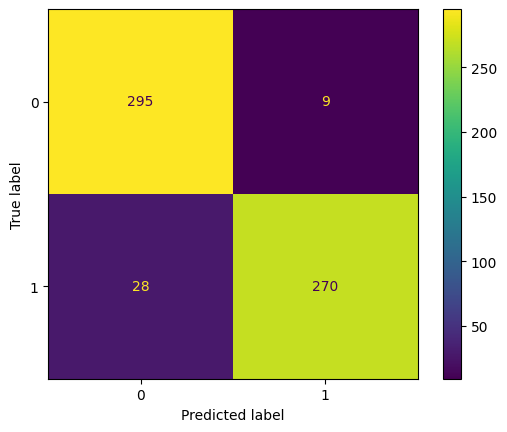

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(max_depth = 12, random_state = 0, n_estimators = 500, n_jobs = -1)

# Random forest classifier - directly on pixel values
RF = RF.fit(X_train, y_train)

y_pred = RF.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

rf_mod_score_nopca = RF.score(X_test, y_test)

print("Train score: %f" % RF.score(X_train, y_train))
print("Test score: %f" % RF.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## SGDClassifier with PCA

              precision    recall  f1-score   support

           0       0.73      0.67      0.70       304
           1       0.69      0.74      0.71       298

    accuracy                           0.71       602
   macro avg       0.71      0.71      0.71       602
weighted avg       0.71      0.71      0.71       602

Train score: 0.783368
Test score: 0.705980
Kappa score: 0.412349


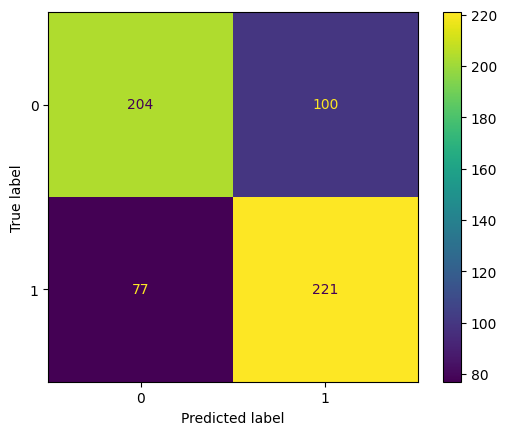

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(loss="modified_huber", max_iter=1000, eta0=1, learning_rate="constant", penalty=None)

# Train the model
sgd.fit(pca_tr.transform(X_train), y_train)

# Make predictions
y_pred = sgd.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

sgd_orig_score_pca = sgd.score(pca_tr.transform(X_test), y_test)

# Evaluate accuracy
print("Train score: %f" % sgd.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % sgd.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))


### Cross validation

In [ ]:
from sklearn.linear_model import SGDClassifier

grid_params = {
    'loss' : ["hinge", "log_loss", "squared_hinge", "modified_huber"],
    'alpha' : [0.0001, 0.001, 0.01, 0.1],
    'penalty' : ["l2", "l1", None],
    'n_jobs' : [-1]
}

gs = GridSearchCV(SGDClassifier(), grid_params, verbose = 1, cv=3, n_jobs = -1)

g_res = gs.fit(pca_tr.transform(X_train), y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 3 folds for each of 48 candidates, totalling 144 fits
0.7521769857503559
{'alpha': 0.1, 'loss': 'hinge', 'n_jobs': -1, 'penalty': 'l2'}


              precision    recall  f1-score   support

           0       0.75      0.69      0.72       304
           1       0.71      0.77      0.74       298

    accuracy                           0.73       602
   macro avg       0.73      0.73      0.73       602
weighted avg       0.73      0.73      0.73       602

Train score: 0.819127
Test score: 0.729236
Kappa score: 0.458830


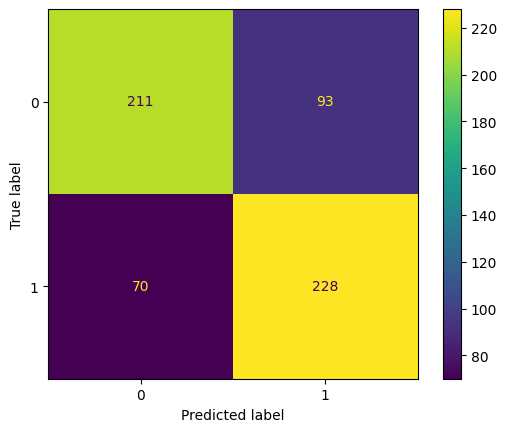

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(loss = "hinge", alpha = 0.1, n_jobs = -1, penalty = 'l2')

# Train the model
sgd.fit(pca_tr.transform(X_train), y_train)

# Make predictions
y_pred = sgd.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

sgd_mod_score_pca = sgd.score(pca_tr.transform(X_test), y_test)

# Evaluate accuracy
print("Train score: %f" % sgd.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % sgd.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))


## SGDClassifier without PCA

              precision    recall  f1-score   support

           0       0.83      0.50      0.62       304
           1       0.64      0.90      0.75       298

    accuracy                           0.70       602
   macro avg       0.74      0.70      0.68       602
weighted avg       0.74      0.70      0.68       602

Train score: 0.851975
Test score: 0.696013
Kappa score: 0.394433


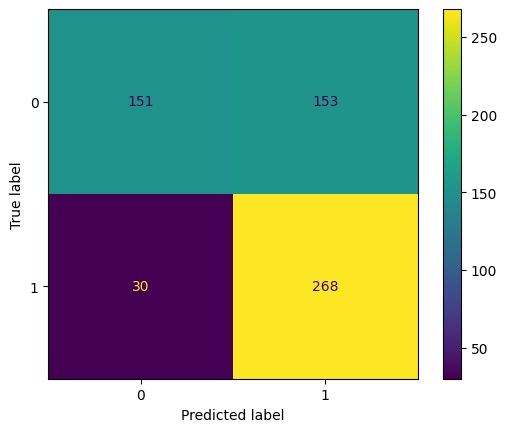

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(loss="modified_huber", max_iter=1000, eta0=1, learning_rate="constant", penalty=None)

# Train the model
sgd.fit(X_train, y_train)

# Make predictions
y_pred = sgd.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

sgd_orig_score_nopca = sgd.score(X_test, y_test)

# Evaluate accuracy
print("Train score: %f" % sgd.score(X_train, y_train))
print("Test score: %f" % sgd.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
from sklearn.linear_model import SGDClassifier

grid_params = {
    'loss' : ["hinge", "log_loss", "squared_hinge", "modified_huber"],
    'alpha' : [0.01, 0.1],
    'penalty' : ["l2", "l1"],
    'n_jobs' : [-1]
}

gs = GridSearchCV(SGDClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 16 candidates, totalling 32 fits
0.8727657423274868
{'alpha': 0.1, 'loss': 'modified_huber', 'n_jobs': -1, 'penalty': 'l2'}


              precision    recall  f1-score   support

           0       0.92      0.83      0.87       304
           1       0.84      0.92      0.88       298

    accuracy                           0.87       602
   macro avg       0.88      0.87      0.87       602
weighted avg       0.88      0.87      0.87       602

Train score: 0.980042
Test score: 0.873754
Kappa score: 0.747734


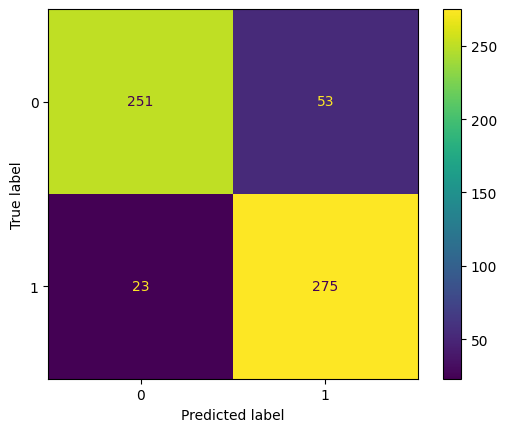

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(loss = "modified_huber", alpha = 0.1, n_jobs = -1, penalty = 'l2')

# Train the model
sgd.fit(X_train, y_train)

# Make predictions
y_pred = sgd.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

sgd_mod_score_nopca = sgd.score(X_test, y_test)

# Evaluate accuracy
print("Train score: %f" % sgd.score(X_train, y_train))
print("Test score: %f" % sgd.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## MLP with PCA

              precision    recall  f1-score   support

           0       0.93      0.94      0.94       304
           1       0.94      0.93      0.93       298

    accuracy                           0.94       602
   macro avg       0.94      0.94      0.94       602
weighted avg       0.94      0.94      0.94       602

Train score: 1.000000
Test score: 0.935216
Kappa score: 0.870406


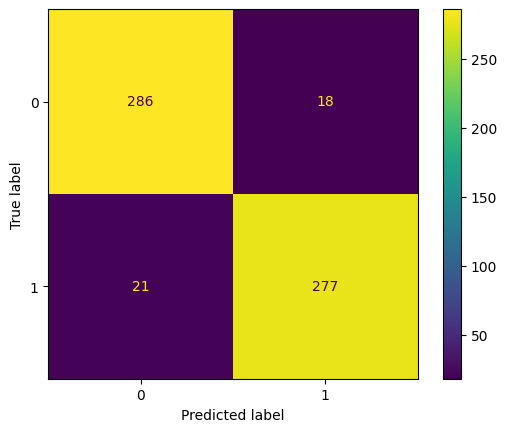

In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
clf = MLPClassifier(random_state=0, max_iter=2000, hidden_layer_sizes=(100,), activation='relu', solver='adam')
clf.fit(pca_tr.transform(X_train), y_train)

# Make predictions
y_pred = clf.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

mlp_orig_score_pca = clf.score(pca_tr.transform(X_test), y_test)

# Evaluate accuracy
print("Train score: %f" % clf.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % clf.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
from sklearn.linear_model import SGDClassifier

grid_params = {
    'hidden_layer_sizes': [(50,50,50), (50,100,50), (100,)],
    'activation': ['tanh', 'relu'],
    'solver': ['sgd', 'adam'],
    'alpha': [0.0001, 0.05],
    'learning_rate': ['constant','adaptive'],
}

gs = GridSearchCV(MLPClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(pca_tr.transform(X_train), y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 48 candidates, totalling 96 fits
0.930145863848421
{'activation': 'relu', 'alpha': 0.05, 'hidden_layer_sizes': (100,), 'learning_rate': 'adaptive', 'solver': 'adam'}


              precision    recall  f1-score   support

           0       0.93      0.93      0.93       304
           1       0.93      0.93      0.93       298

    accuracy                           0.93       602
   macro avg       0.93      0.93      0.93       602
weighted avg       0.93      0.93      0.93       602

Train score: 1.000000
Test score: 0.931894
Kappa score: 0.863769


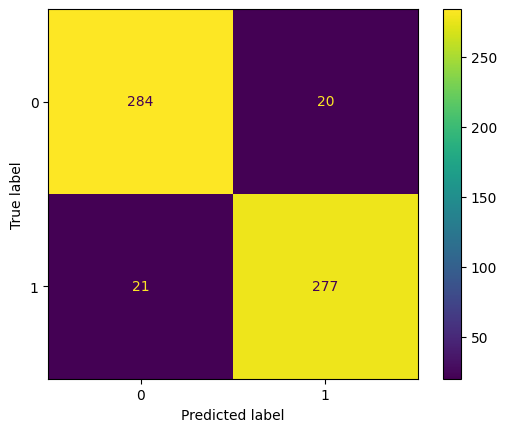

In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
clf = MLPClassifier(max_iter=2000, activation = 'relu', hidden_layer_sizes = (100,), learning_rate = 'adaptive', solver = 'adam')
clf.fit(pca_tr.transform(X_train), y_train)

# Make predictions
y_pred = clf.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

mlp_mod_score_pca = clf.score(pca_tr.transform(X_test), y_test)

# Evaluate accuracy
print("Train score: %f" % clf.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % clf.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## MLP without PCA

              precision    recall  f1-score   support

           0       0.86      0.87      0.86       304
           1       0.86      0.86      0.86       298

    accuracy                           0.86       602
   macro avg       0.86      0.86      0.86       602
weighted avg       0.86      0.86      0.86       602

Train score: 0.879834
Test score: 0.862126
Kappa score: 0.724216


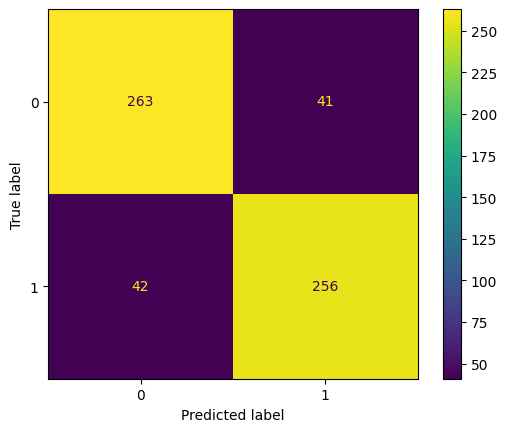

In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
clf = MLPClassifier(random_state=0, max_iter=2000, hidden_layer_sizes=(100,), activation='relu', solver='adam')
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

mlp_orig_score_nopca = clf.score(X_test, y_test)

# Evaluate accuracy
print("Train score: %f" % clf.score(X_train, y_train))
print("Test score: %f" % clf.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
grid_params = {
    'hidden_layer_sizes': [(50,50,50), (50,100,50), (100,)],
    'activation': ['tanh', 'relu'],
    'solver': ['sgd', 'adam'],
    'alpha': [0.0001, 0.05],
    'learning_rate': ['constant','adaptive'],
    'max_iter' : [5]
}

gs = GridSearchCV(MLPClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 48 candidates, totalling 96 fits


/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


0.7567558502523503
{'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (100,), 'learning_rate': 'constant', 'max_iter': 5, 'solver': 'sgd'}


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5) reached and the optimization hasn't converged yet.
  warnings.warn(


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:697: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


              precision    recall  f1-score   support

           0       0.96      0.94      0.95       304
           1       0.94      0.96      0.95       298

    accuracy                           0.95       602
   macro avg       0.95      0.95      0.95       602
weighted avg       0.95      0.95      0.95       602

Train score: 0.999168
Test score: 0.951827
Kappa score: 0.903661


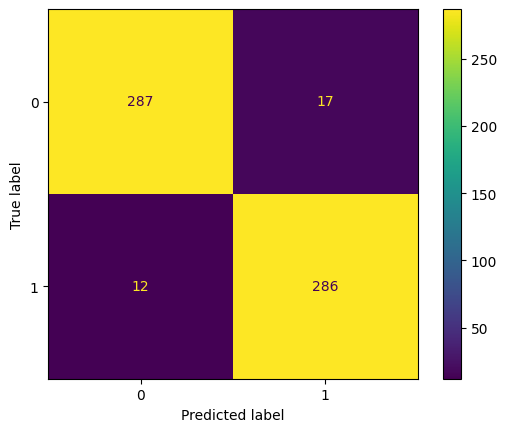

In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
clf = MLPClassifier(max_iter=2000, activation = 'relu', alpha = 0.0001, hidden_layer_sizes = (100,), learning_rate = 'constant', solver = 'sgd')
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

mlp_mod_score_nopca = clf.score(X_test, y_test)

# Evaluate accuracy
print("Train score: %f" % clf.score(X_train, y_train))
print("Test score: %f" % clf.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## CNN without PCA

In [ ]:
model = tf.keras.Sequential([
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])

In [ ]:
model.compile(
  optimizer="adam",
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])

In [ ]:
epochs = 15

history = model.fit(
  transformed_X_train, y_train,
  validation_data=(transformed_X_test, y_test), shuffle=True,
  epochs=epochs, batch_size=32
)

Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 49s 630ms/step - accuracy: 0.7868 - loss: 2.2703 - val_accuracy: 0.9203 - val_loss: 0.2036
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 71s 484ms/step - accuracy: 0.9295 - loss: 0.1762 - val_accuracy: 0.9236 - val_loss: 0.2034
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 37s 490ms/step - accuracy: 0.9555 - loss: 0.1199 - val_accuracy: 0.9385 - val_loss: 0.1940
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 495ms/step - accuracy: 0.9763 - loss: 0.0720 - val_accuracy: 0.9385 - val_loss: 0.2161
Epoch 5/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 489ms/step - accuracy: 0.9755 - loss: 0.0654 - val_accuracy: 0.9452 - val_loss: 0.1839
Epoch 6/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 492ms/step - accuracy: 0.9905 - loss: 0.0291 - val_accuracy: 0.9369 - val_loss: 0.1995
Epoch 7/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 46s 563ms/step - accuracy: 0.9911 - loss: 0.0351 - val_accuracy: 0.9502 - val_loss: 0.1650
Epoch 8/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 78s 507ms/step - accuracy: 0.9942 - loss: 0.0273 - val_accu

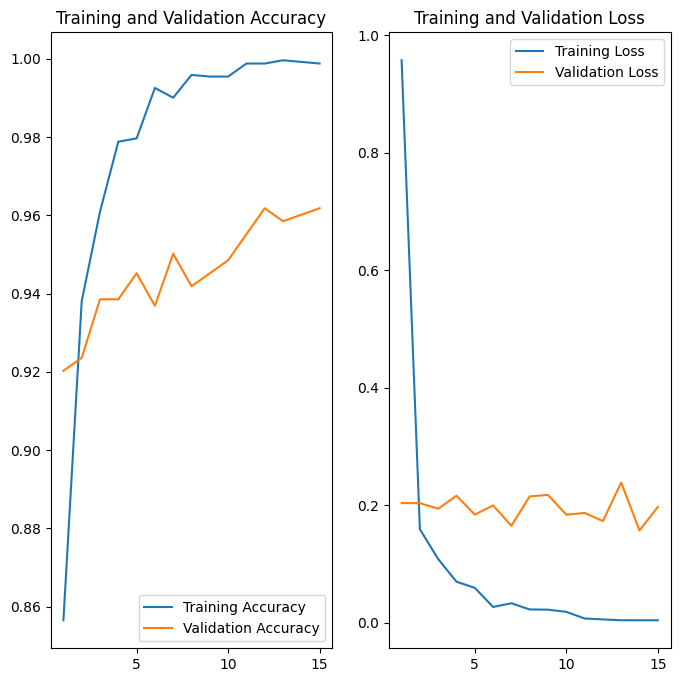

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(transformed_X_test, y_test, verbose=2)

cnn_orig_score_nopca = test_acc

19/19 - 2s - 110ms/step - accuracy: 0.9618 - loss: 0.1969


In [ ]:
# Function to create model, required for KerasClassifier

def create_model(optimizer='adam'):
  # create model
  model = tf.keras.Sequential()
  model.add(tf.keras.layers.Conv2D(32, 5, activation='relu'))
  model.add(tf.keras.layers.MaxPooling2D())
  model.add(tf.keras.layers.Flatten())
  model.add(tf.keras.layers.Dense(128, activation='relu'))
  model.add(tf.keras.layers.Dense(1, activation='sigmoid'))

	# Compile mode
  model.compile(
  #optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
  optimizer=optimizer,
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])
  return model

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=6, verbose=1)
mc = tf.keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

# create model
model = KerasClassifier(model=create_model, verbose=0)

# define the grid search parameters
batch_size = [10, 20, 40, 60, 80, 100]
epochs = [15]
optimizer = ['SGD', 'RMSprop', 'Adagrad', 'Adadelta', 'Adam', 'Adamax', 'Nadam']
param_grid = dict(batch_size=batch_size, epochs=epochs, model__optimizer=optimizer)

grid = GridSearchCV(estimator=model, param_grid=param_grid, n_jobs=-1, cv=3)
grid_result = grid.fit(transformed_X_train, y_train)
# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

ValueError: 
All the 126 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.10/dist-packages/scikeras/wrappers.py", line 1501, in fit
    super().fit(X=X, y=y, sample_weight=sample_weight, **kwargs)
  File "/usr/local/lib/python3.10/dist-packages/scikeras/wrappers.py", line 770, in fit
    self._fit(
  File "/usr/local/lib/python3.10/dist-packages/scikeras/wrappers.py", line 936, in _fit
    self._check_model_compatibility(y)
  File "/usr/local/lib/python3.10/dist-packages/scikeras/wrappers.py", line 559, in _check_mode

### Cross validation

In [ ]:
# clear session
tf.keras.backend.clear_session(
    free_memory=True
)

In [ ]:
transformed_X_train = []
transformed_X_test = []

for img in X_train:
  img = np.reshape(img,(128, 128, 3))
  transformed_X_train.append(img)

for img in X_test:
  img = np.reshape(img,(128, 128, 3))
  transformed_X_test.append(img)

transformed_X_train = np.array(transformed_X_train)
transformed_X_test = np.array(transformed_X_test)

img = []

print(transformed_X_train.shape)
print(transformed_X_test.shape)

(2405, 128, 128, 3)
(602, 128, 128, 3)


In [ ]:
model = tf.keras.Sequential([
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Flatten(),
  #tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(256, activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])
model.compile(
  optimizer="adam",
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=6, verbose=1)
mc = tf.keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

epochs = 15

history = model.fit(
  transformed_X_train, y_train,
  validation_data=(transformed_X_test, y_test), shuffle=True,
  epochs=epochs, batch_size=32, callbacks = [es, mc]
)


Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - accuracy: 0.6794 - loss: 4.1454
Epoch 1: val_loss improved from inf to 0.25148, saving model to best_model.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 71s 893ms/step - accuracy: 0.6809 - loss: 4.1103 - val_accuracy: 0.9086 - val_loss: 0.2515
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - accuracy: 0.9052 - loss: 0.2432
Epoch 2: val_loss improved from 0.25148 to 0.22644, saving model to best_model.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 77s 831ms/step - accuracy: 0.9054 - loss: 0.2429 - val_accuracy: 0.9037 - val_loss: 0.2264
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 613ms/step - accuracy: 0.9276 - loss: 0.1760
Epoch 3: val_loss improved from 0.22644 to 0.21946, saving model to best_model.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 88s 918ms/step - accuracy: 0.9278 - loss: 0.1757 - val_accuracy: 0.9120 - val_loss: 0.2195
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 626ms/step - accuracy: 0.9571 - loss: 0.1211
Epoch 4: val_loss improved from 0.21946 to 0.17310,

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 124, 124, 32)        │           2,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 62, 62, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 123008)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      15,745,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 47,267,717 (180.31 MB)

 Trainable params: 15,755,905 (60.10 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 31,511,812 (120.21 MB)

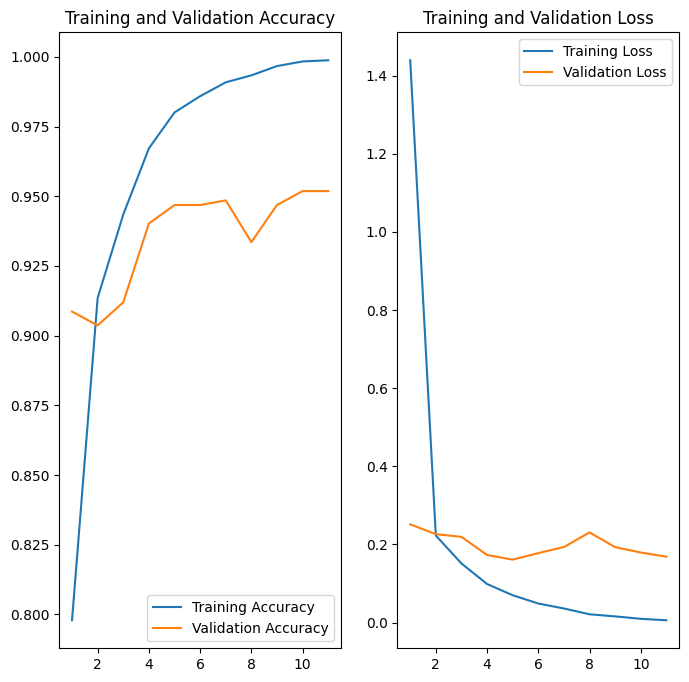

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(transformed_X_test, y_test, verbose=2)

cnn_mod_score_nopca = test_acc

19/19 - 2s - 120ms/step - accuracy: 0.9518 - loss: 0.1688


In [ ]:
y_pred = clf.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % clf.score(X_train, y_train))
print("Test score: %f" % clf.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## CNN with PCA

In [ ]:
import tensorflow as tf

# clear session
tf.keras.backend.clear_session(
    free_memory=True
)

In [ ]:
# Reconstruct train images from the first 300 bases

projims = pca_tr.transform(X_train)
transformed_X_train = []
for k in range(0,len(projims)):
  res = np.zeros((SIZE*SIZE*3))
  for i in range(300):
    res += pca_tr.components_[i].dot(projims[k,i])
  transformed_X_train.append(res)

# Reconstruct test images from the first 300 bases

projims = pca_tr.transform(X_test)
transformed_X_test = []
for k in range(0,len(projims)):
  res = np.zeros((SIZE*SIZE*3))
  for i in range(300):
    res += pca_tr.components_[i].dot(projims[k,i])
  transformed_X_test.append(res)

transformed_X_train = np.array(transformed_X_train)
transformed_X_test = np.array(transformed_X_test)

projims = []
res = []

In [ ]:
print(transformed_X_train.shape)
print(transformed_X_test.shape)

(2405, 49152)
(602, 49152)


In [ ]:
unflattened_X_train = []
unflattened_X_test = []

for img in transformed_X_train:
  img = np.reshape(img,(128, 128, 3))
  unflattened_X_train.append(img)

for img in transformed_X_test:
  img = np.reshape(img,(128, 128, 3))
  unflattened_X_test.append(img)

unflattened_X_train = np.array(unflattened_X_train)
unflattened_X_test = np.array(unflattened_X_test)

img = []
transformed_X_train = []
transformed_X_test = []

print(unflattened_X_train.shape)
print(unflattened_X_test.shape)

(2405, 128, 128, 3)
(602, 128, 128, 3)


In [ ]:
model = tf.keras.Sequential([
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Flatten(),
  #tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])

In [ ]:
model.compile(
  #optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
  optimizer="adam",
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])

#es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=6, verbose=1)
#mc = tf.keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

In [ ]:
epochs = 15

history = model.fit(
  unflattened_X_train, y_train,
  validation_data=(unflattened_X_test, y_test), shuffle=True,
  epochs=epochs, batch_size=32
)

Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 39s 497ms/step - accuracy: 0.7380 - loss: 1.3176 - val_accuracy: 0.8821 - val_loss: 0.2867
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 40s 489ms/step - accuracy: 0.9091 - loss: 0.2328 - val_accuracy: 0.9103 - val_loss: 0.2415
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 490ms/step - accuracy: 0.9376 - loss: 0.1646 - val_accuracy: 0.9186 - val_loss: 0.2269
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 42s 506ms/step - accuracy: 0.9536 - loss: 0.1245 - val_accuracy: 0.9236 - val_loss: 0.2265
Epoch 5/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 40s 493ms/step - accuracy: 0.9659 - loss: 0.0953 - val_accuracy: 0.9269 - val_loss: 0.2188
Epoch 6/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 491ms/step - accuracy: 0.9735 - loss: 0.0777 - val_accuracy: 0.9053 - val_loss: 0.2791
Epoch 7/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 491ms/step - accuracy: 0.9704 - loss: 0.0733 - val_accuracy: 0.9203 - val_loss: 0.2317
Epoch 8/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 492ms/step - accuracy: 0.9758 - loss: 0.0645 - val_accu

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 124, 124, 32)        │           2,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 62, 62, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 123008)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      15,745,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 47,243,141 (180.22 MB)

 Trainable params: 15,747,713 (60.07 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 31,495,428 (120.15 MB)

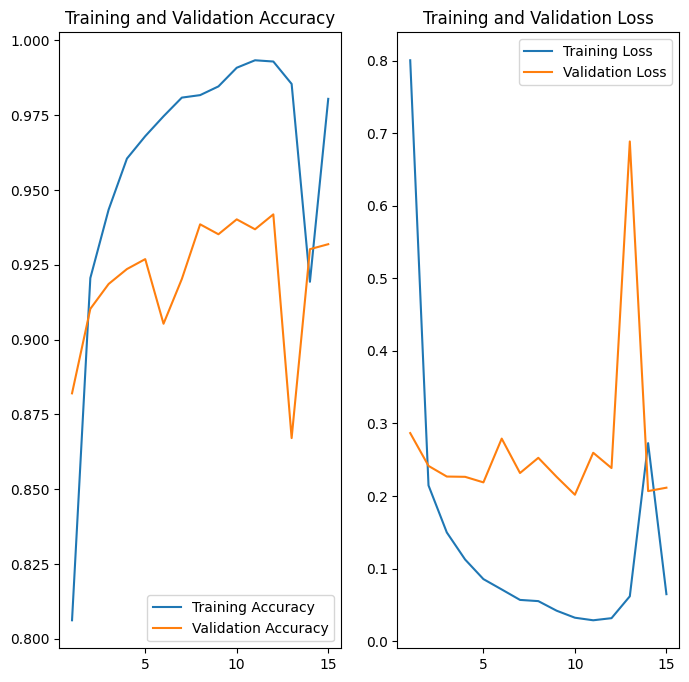

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(unflattened_X_test, y_test, verbose=2)

cnn_orig_score_pca = test_acc

19/19 - 2s - 106ms/step - accuracy: 0.9319 - loss: 0.2115


### Cross validation

In [ ]:
model = tf.keras.Sequential([
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(256, activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])

In [ ]:
model.compile(
  optimizer="adam",
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=6, verbose=1)
mc = tf.keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)
epochs = 15

history = model.fit(
  unflattened_X_train, y_train,
  validation_data=(unflattened_X_test, y_test), shuffle=True,
  epochs=epochs, batch_size=32
)


Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 60s 764ms/step - accuracy: 0.7809 - loss: 0.4888 - val_accuracy: 0.9020 - val_loss: 0.2815
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 75s 681ms/step - accuracy: 0.9038 - loss: 0.2453 - val_accuracy: 0.9186 - val_loss: 0.2422
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 82s 682ms/step - accuracy: 0.9374 - loss: 0.1580 - val_accuracy: 0.9086 - val_loss: 0.2647
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 53s 704ms/step - accuracy: 0.9497 - loss: 0.1256 - val_accuracy: 0.9219 - val_loss: 0.2529
Epoch 5/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 80s 683ms/step - accuracy: 0.9653 - loss: 0.1083 - val_accuracy: 0.9252 - val_loss: 0.2359
Epoch 6/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 82s 676ms/step - accuracy: 0.9580 - loss: 0.1242 - val_accuracy: 0.9402 - val_loss: 0.2315
Epoch 7/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 82s 684ms/step - accuracy: 0.9827 - loss: 0.0471 - val_accuracy: 0.9319 - val_loss: 0.2395
Epoch 8/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 81s 676ms/step - accuracy: 0.9929 - loss: 0.0322 - val_accu

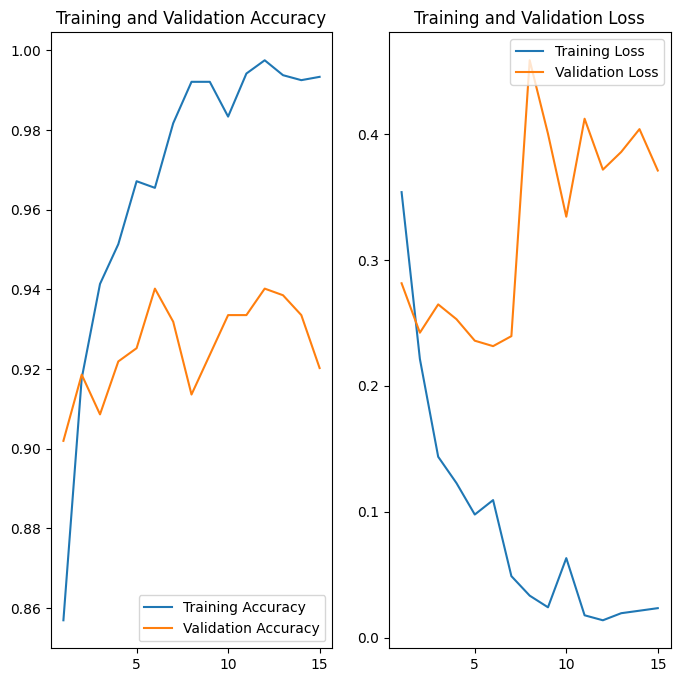

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(unflattened_X_test, y_test, verbose=2)

cnn_mod_score_pca = test_acc

19/19 - 4s - 219ms/step - accuracy: 0.9203 - loss: 0.3710


## Pre-trained model with coloured images

In [ ]:
import pathlib

data_dir = pathlib.Path('/content/drive/MyDrive/ML_IPData7/Datasets/').with_suffix('')
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

1876


In [ ]:
batch_size = 32
img_height = 128
img_width = 128

train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  labels = "inferred",
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  labels = "inferred",
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)



Found 1876 files belonging to 2 classes.
Using 1501 files for training.
Found 1876 files belonging to 2 classes.
Using 375 files for validation.


In [ ]:
print(val_ds)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [ ]:
IMG_SHAPE = (128, 128, 3)

base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               weights='imagenet')


In [ ]:
image_batch, label_batch = next(iter(train_ds))
feature_batch = base_model(image_batch)
print(feature_batch.shape)

(32, 4, 4, 1280)


In [ ]:
base_model.trainable = False
base_model.summary()

Model: "mobilenetv2_1.00_128"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4             │ (None, 128, 128, 3)    │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ Conv1 (Conv2D)            │ (None, 64, 64, 32)     │            864 │ input_layer_4[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ bn_Conv1                  │ (None, 64, 64, 32)     │            128 │ Conv1[0][0]            │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ Conv1_relu (ReLU)         │ (None, 64, 64, 32)     │              0 │ bn_Conv1[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_depthwise   │ (None, 64, 64, 32)     │            288 │ Conv1_relu[0][0]       │
│ (DepthwiseConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_depthwise_… │ (None, 64, 64, 32)     │            128 │ expanded_conv_depthwi… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_depthwise_… │ (None, 64, 64, 32)     │              0 │ expanded_conv_depthwi… │
│ (ReLU)                    │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_project     │ (None, 64, 64, 16)     │            512 │ expanded_conv_depthwi… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_project_BN  │ (None, 64, 64, 16)     │             64 │ expanded_conv_project… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_expand (Conv2D)   │ (None, 64, 64, 96)     │          1,536 │ expanded_conv_project… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_expand_BN         │ (None, 64, 64, 96)     │            384 │ block_1_expand[0][0]   │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_expand_relu       │ (None, 64, 64, 96)     │              0 │ block_1_expand_BN[0][… │
│ (ReLU)                    │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_pad               │ (None, 65, 65, 96)     │              0 │ block_1_expand_relu[0… │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_depthwise         │ (None, 32, 32, 96)     │            864 │ block_1_pad[0][0]      │
│ (DepthwiseConv2D)         │                        │                │                        │
├──────────────────────

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

(32, 1280)


In [ ]:
prediction_layer = tf.keras.layers.Dense(1, activation='sigmoid')
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)

(32, 1)


In [ ]:
inputs = tf.keras.Input(shape=(128, 128, 3))
x = inputs
x = base_model(x, training=False)
x = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

In [ ]:
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)           │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_128 (Functional)    │ (None, 4, 4, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

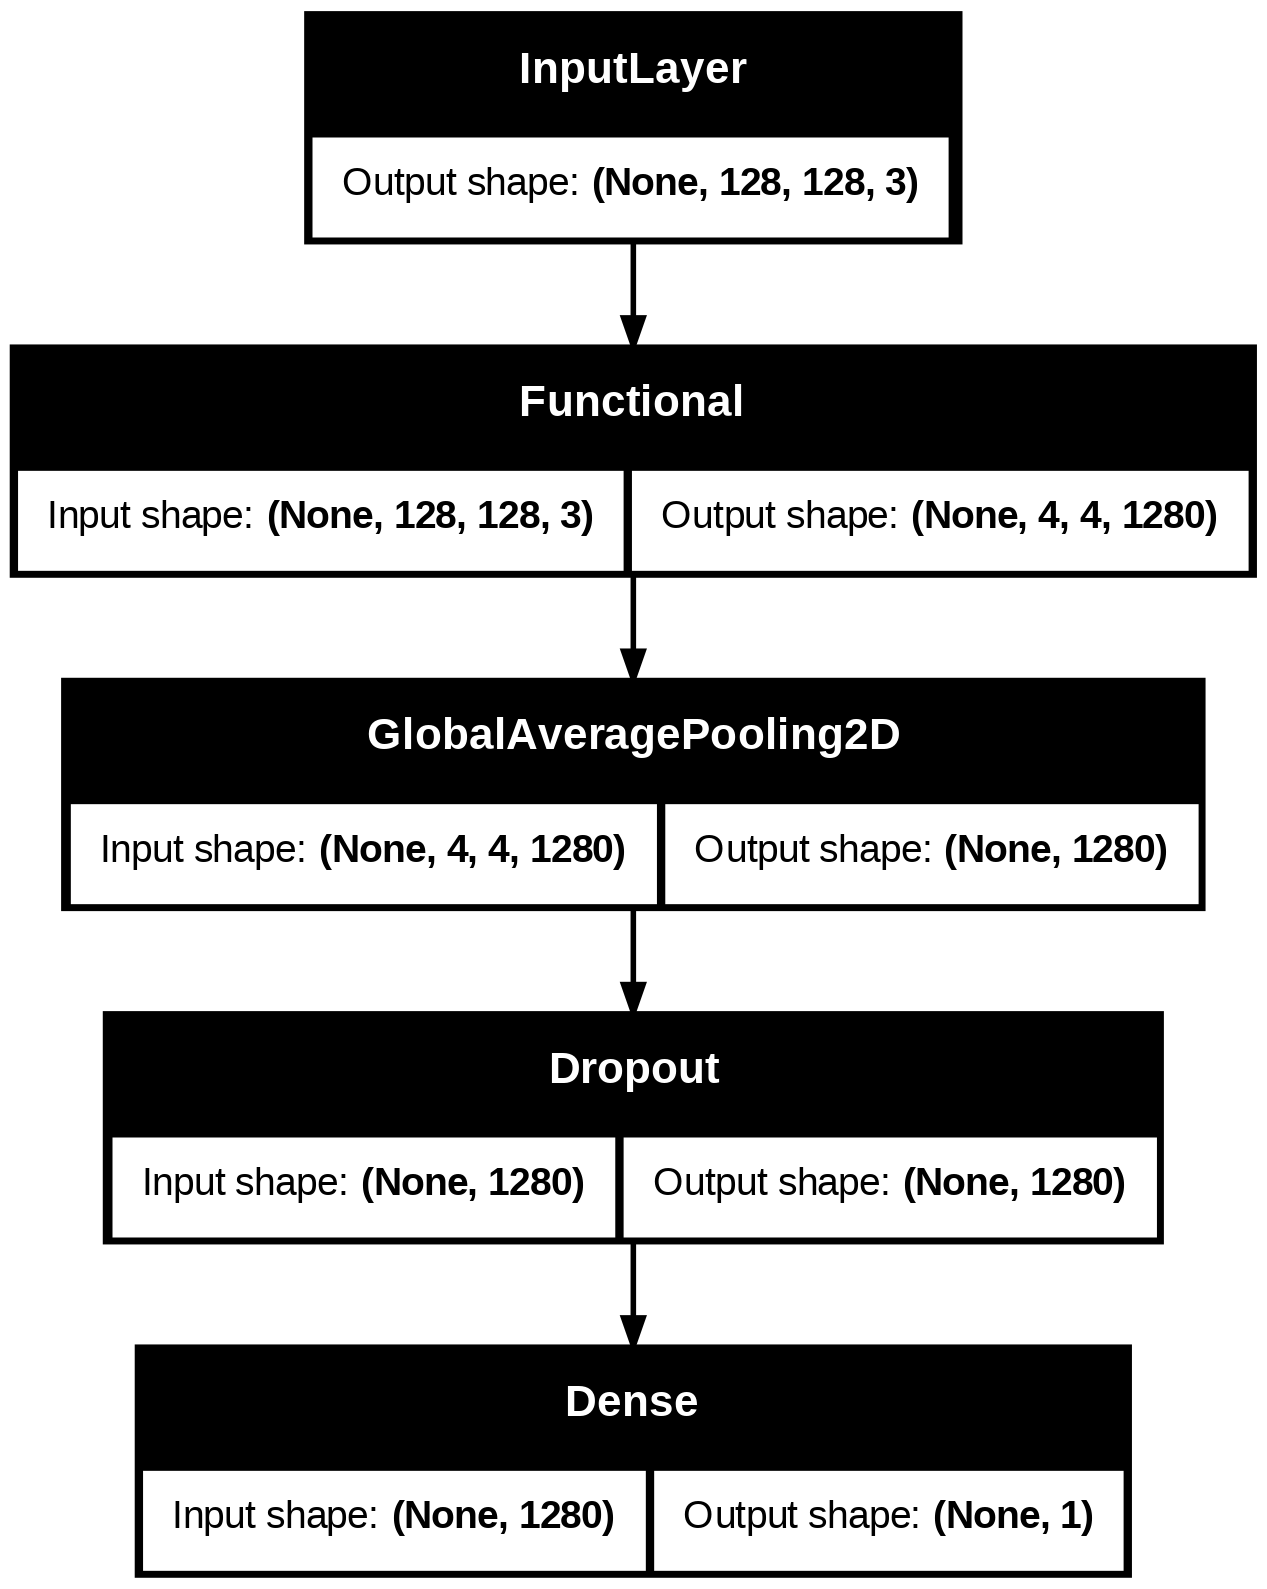

In [ ]:
tf.keras.utils.plot_model(model, show_shapes=True)

In [ ]:
base_learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[tf.keras.metrics.BinaryAccuracy(threshold=0.5, name='accuracy')])

In [ ]:
print(val_ds)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [ ]:
initial_epochs = 10

loss0, accuracy0 = model.evaluate(val_ds)

12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 756ms/step - accuracy: 0.7273 - loss: 0.5960


In [ ]:
print("initial loss: {:.2f}".format(loss0))
print("initial accuracy: {:.2f}".format(accuracy0))

initial loss: 0.62
initial accuracy: 0.68


In [ ]:
history = model.fit(train_ds,
                    epochs=initial_epochs,
                    validation_data=val_ds)

Epoch 1/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 36s 622ms/step - accuracy: 0.6801 - loss: 0.6062 - val_accuracy: 0.8107 - val_loss: 0.4267
Epoch 2/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 28s 587ms/step - accuracy: 0.8128 - loss: 0.4642 - val_accuracy: 0.8293 - val_loss: 0.3857
Epoch 3/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 41s 594ms/step - accuracy: 0.8214 - loss: 0.4392 - val_accuracy: 0.8640 - val_loss: 0.3522
Epoch 4/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 38s 539ms/step - accuracy: 0.8508 - loss: 0.3856 - val_accuracy: 0.8720 - val_loss: 0.3260
Epoch 5/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 41s 550ms/step - accuracy: 0.8755 - loss: 0.3641 - val_accuracy: 0.8773 - val_loss: 0.3049
Epoch 6/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 41s 540ms/step - accuracy: 0.8750 - loss: 0.3450 - val_accuracy: 0.8907 - val_loss: 0.2882
Epoch 7/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 41s 542ms/step - accuracy: 0.9002 - loss: 0.3065 - val_accuracy: 0.8960 - val_loss: 0.2743
Epoch 8/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 40s 529ms/step - accuracy: 0.8870 - loss: 0.3331 - val_accu

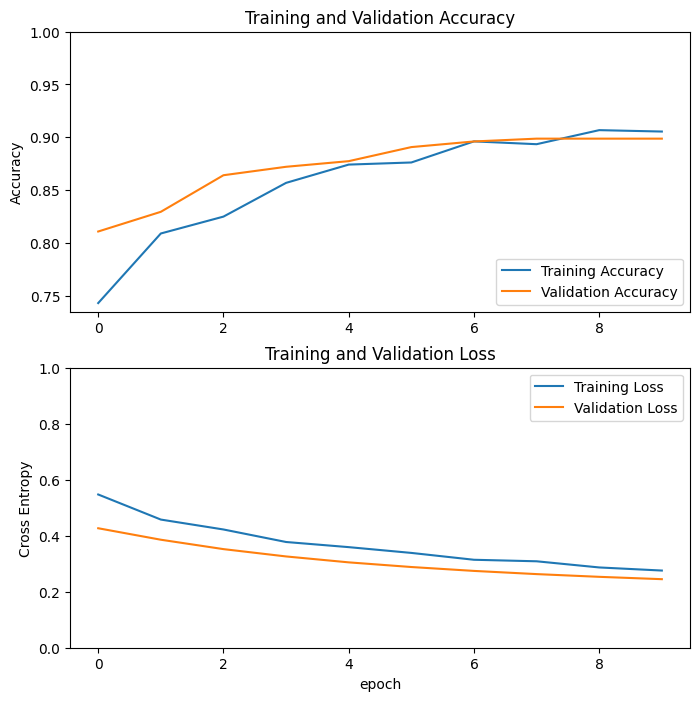

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(val_ds)

12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 501ms/step - accuracy: 0.9035 - loss: 0.2515


## Pre-trained model with coloured images modified

In [ ]:
import tensorflow as tf

# clear session
tf.keras.backend.clear_session(
    free_memory=True
)

In [ ]:
import pathlib

data_dir = pathlib.Path('/content/drive/MyDrive/ML_IPData7/Datasets/').with_suffix('')
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

1876


In [ ]:
batch_size = 32
img_height = 128
img_width = 128

train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  labels = "inferred",
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  labels = "inferred",
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)



Found 1876 files belonging to 2 classes.
Using 1501 files for training.
Found 1876 files belonging to 2 classes.
Using 375 files for validation.


In [ ]:
print(val_ds)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [ ]:
IMG_SHAPE = (128, 128, 3)

base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               weights='imagenet')


In [ ]:
image_batch, label_batch = next(iter(train_ds))
feature_batch = base_model(image_batch)
print(feature_batch.shape)

(32, 4, 4, 1280)


In [ ]:
base_model.trainable = False
base_model.summary()

Model: "mobilenetv2_1.00_128"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 128, 128, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ Conv1 (Conv2D)            │ (None, 64, 64, 32)     │            864 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ bn_Conv1                  │ (None, 64, 64, 32)     │            128 │ Conv1[0][0]            │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ Conv1_relu (ReLU)         │ (None, 64, 64, 32)     │              0 │ bn_Conv1[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_depthwise   │ (None, 64, 64, 32)     │            288 │ Conv1_relu[0][0]       │
│ (DepthwiseConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_depthwise_… │ (None, 64, 64, 32)     │            128 │ expanded_conv_depthwi… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_depthwise_… │ (None, 64, 64, 32)     │              0 │ expanded_conv_depthwi… │
│ (ReLU)                    │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_project     │ (None, 64, 64, 16)     │            512 │ expanded_conv_depthwi… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_project_BN  │ (None, 64, 64, 16)     │             64 │ expanded_conv_project… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_expand (Conv2D)   │ (None, 64, 64, 96)     │          1,536 │ expanded_conv_project… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_expand_BN         │ (None, 64, 64, 96)     │            384 │ block_1_expand[0][0]   │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_expand_relu       │ (None, 64, 64, 96)     │              0 │ block_1_expand_BN[0][… │
│ (ReLU)                    │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_pad               │ (None, 65, 65, 96)     │              0 │ block_1_expand_relu[0… │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_depthwise         │ (None, 32, 32, 96)     │            864 │ block_1_pad[0][0]      │
│ (DepthwiseConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_depthwise_BN 

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

(32, 1280)


In [ ]:
prediction_layer = tf.keras.layers.Dense(1, activation='sigmoid')
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)

(32, 1)


In [ ]:
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.2),
])
rescale = tf.keras.layers.Rescaling(1./127.5, offset=-1)

In [ ]:
inputs = tf.keras.Input(shape=(128, 128, 3))
x = data_augmentation(inputs)
x = rescale(x)
x = base_model(x, training=False)
x = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

In [ ]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential (Sequential)              │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_128 (Functional)    │ (None, 4, 4, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

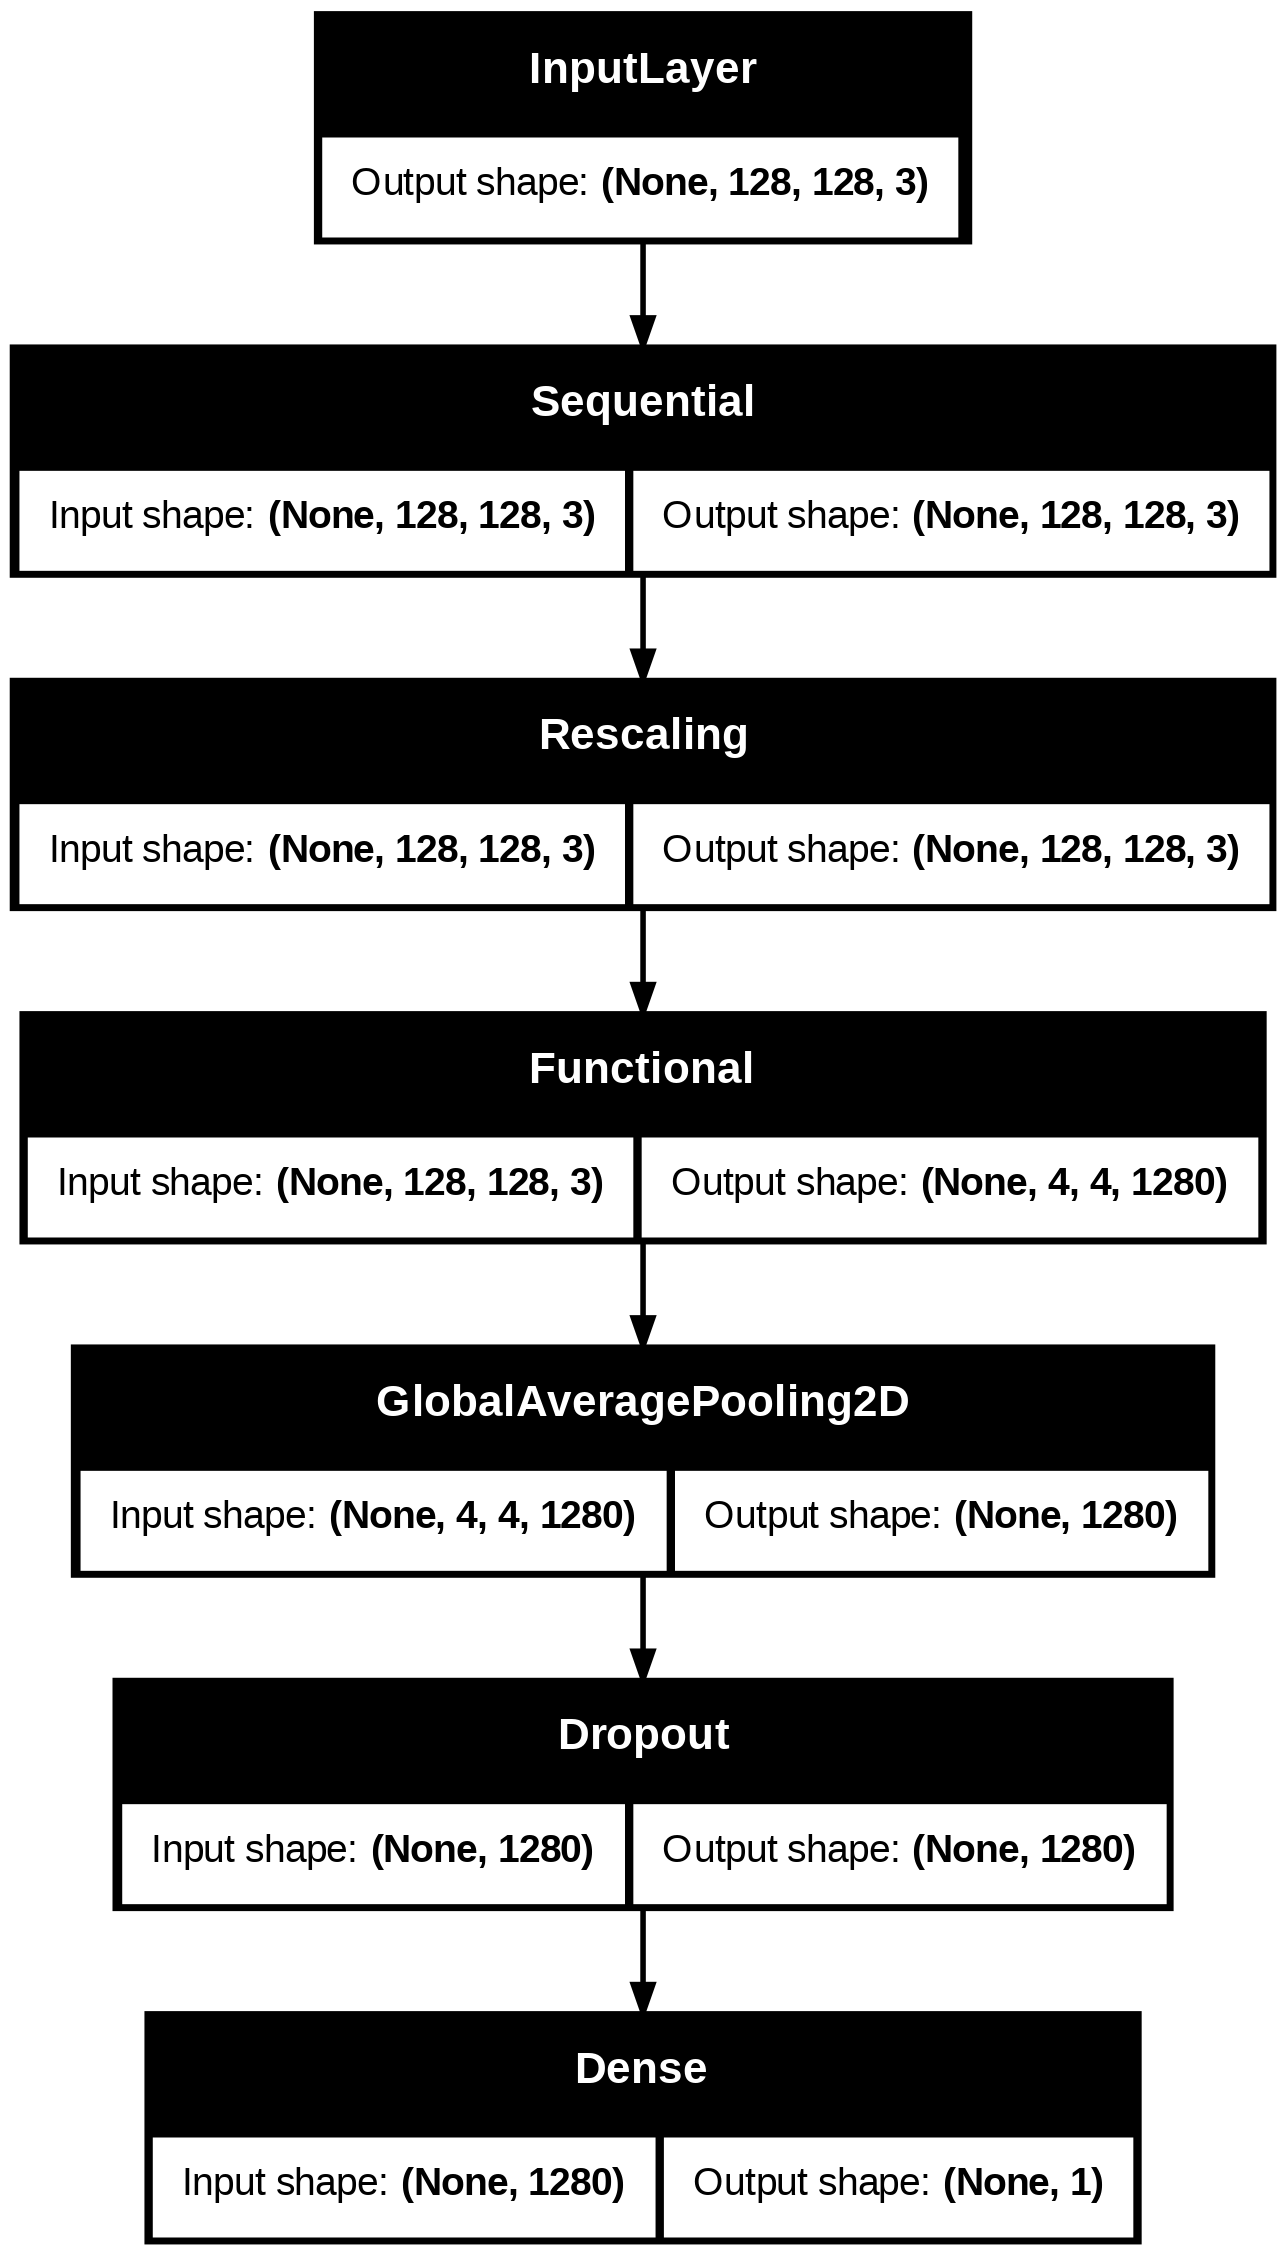

In [ ]:
tf.keras.utils.plot_model(model, show_shapes=True)

In [ ]:
base_learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[tf.keras.metrics.BinaryAccuracy(threshold=0.5, name='accuracy')])

In [ ]:
print(val_ds)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [ ]:
initial_epochs = 10

loss0, accuracy0 = model.evaluate(val_ds)

12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 574ms/step - accuracy: 0.1756 - loss: 1.4572


In [ ]:
print("initial loss: {:.2f}".format(loss0))
print("initial accuracy: {:.2f}".format(accuracy0))

initial loss: 1.46
initial accuracy: 0.19


In [ ]:
history = model.fit(train_ds,
                    epochs=initial_epochs,
                    validation_data=val_ds)

Epoch 1/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 50s 805ms/step - accuracy: 0.2785 - loss: 1.2818 - val_accuracy: 0.6080 - val_loss: 0.6598
Epoch 2/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 30s 620ms/step - accuracy: 0.6402 - loss: 0.6603 - val_accuracy: 0.8347 - val_loss: 0.4439
Epoch 3/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 41s 629ms/step - accuracy: 0.8097 - loss: 0.4530 - val_accuracy: 0.8853 - val_loss: 0.3283
Epoch 4/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 30s 641ms/step - accuracy: 0.8425 - loss: 0.3610 - val_accuracy: 0.9200 - val_loss: 0.2532
Epoch 5/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 41s 638ms/step - accuracy: 0.9010 - loss: 0.2913 - val_accuracy: 0.9520 - val_loss: 0.2032
Epoch 6/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 44s 699ms/step - accuracy: 0.9250 - loss: 0.2145 - val_accuracy: 0.9547 - val_loss: 0.1684
Epoch 7/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 37s 596ms/step - accuracy: 0.9490 - loss: 0.1720 - val_accuracy: 0.9600 - val_loss: 0.1425
Epoch 8/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 44s 668ms/step - accuracy: 0.9594 - loss: 0.1466 - val_accu

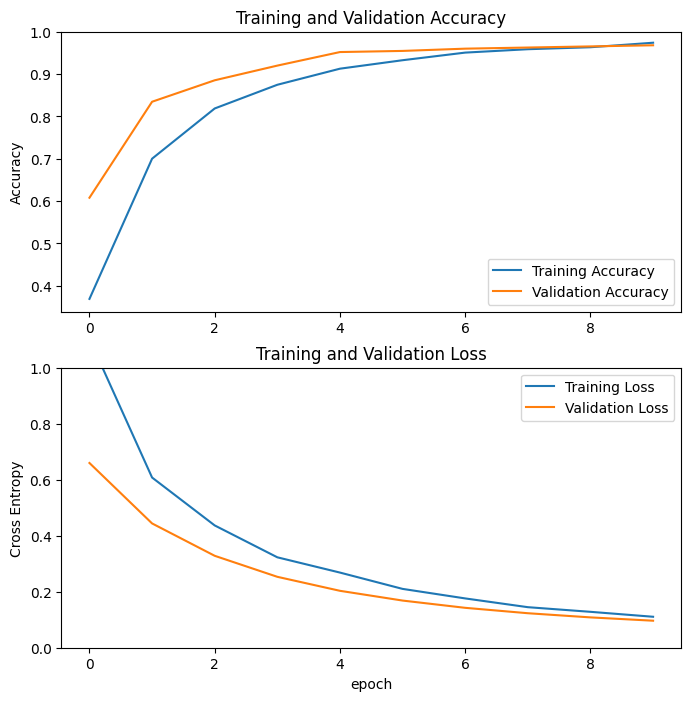

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(val_ds)

12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 359ms/step - accuracy: 0.9614 - loss: 0.0992


In [ ]:
# Unfreeze the base_model. Note that it keeps running in inference mode
# since we passed `training=False` when calling it. This means that
# the batchnorm layers will not update their batch statistics.
# This prevents the batchnorm layers from undoing all the training
# we've done so far.
base_model.trainable = True
model.summary()

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),  # Low learning rate
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[keras.metrics.BinaryAccuracy()],
)

epochs = 10
history = model.fit(train_ds, epochs=epochs, validation_data=val_ds)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential (Sequential)              │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_128 (Functional)    │ (None, 4, 4, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,261,829 (8.63 MB)

 Trainable params: 2,225,153 (8.49 MB)

 Non-trainable params: 34,112 (133.25 KB)

 Optimizer params: 2,564 (10.02 KB)

Epoch 1/10


/usr/local/lib/python3.10/dist-packages/keras/src/backend/tensorflow/nn.py:707: UserWarning: "`binary_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Sigmoid activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


47/47 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - binary_accuracy: 0.8810 - loss: 0.3150 - val_binary_accuracy: 0.9867 - val_loss: 0.0619
Epoch 2/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 95s 2s/step - binary_accuracy: 0.9639 - loss: 0.1753 - val_binary_accuracy: 0.9867 - val_loss: 0.0563
Epoch 3/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - binary_accuracy: 0.9589 - loss: 0.1477 - val_binary_accuracy: 0.9893 - val_loss: 0.0565
Epoch 4/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 191s 3s/step - binary_accuracy: 0.9785 - loss: 0.1025 - val_binary_accuracy: 0.9893 - val_loss: 0.0540
Epoch 5/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - binary_accuracy: 0.9843 - loss: 0.0832 - val_binary_accuracy: 0.9867 - val_loss: 0.0528
Epoch 6/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - binary_accuracy: 0.9869 - loss: 0.0634 - val_binary_accuracy: 0.9893 - val_loss: 0.0501
Epoch 7/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 139s 2s/step - binary_accuracy: 0.9911 - loss: 0.0603 - val_binary_accuracy: 0.9867 - val_loss: 0.0489
Epoch 8/10
47/47 ━━━━━━━━

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

KeyError: 'accuracy'

In [ ]:
test_loss, test_acc = model.evaluate(val_ds)

pre_mod_acc = test_acc

12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 876ms/step - binary_accuracy: 0.9932 - loss: 0.0306


# Coloured images with HOG

In [ ]:
transformed_X_train = []
transformed_X_test = []

for img in X_train:
  img = np.reshape(img,(128, 128, 3))
  fd, img = hog(
    img,
    orientations=9,
    pixels_per_cell=(9, 9),
    cells_per_block=(2, 2),
    visualize=True,
    channel_axis=-1)
  img = img.reshape((img.shape[0] * img.shape[1]))
  transformed_X_train.append(img)

for img in X_test:
  img = np.reshape(img,(128, 128, 3))
  fd, img = hog(
    img,
    orientations=9,
    pixels_per_cell=(9, 9),
    cells_per_block=(2, 2),
    visualize=True,
    channel_axis=-1)
  img = img.reshape((img.shape[0] * img.shape[1]))
  transformed_X_test.append(img)

transformed_X_train = np.array(transformed_X_train)
transformed_X_test = np.array(transformed_X_test)

img = []

print(transformed_X_train.shape)
print(transformed_X_test.shape)

(2405, 16384)
(602, 16384)


## KNN hog

              precision    recall  f1-score   support

           0       0.91      0.98      0.94       304
           1       0.98      0.90      0.94       298

    accuracy                           0.94       602
   macro avg       0.94      0.94      0.94       602
weighted avg       0.94      0.94      0.94       602

Train score: 0.945530
Test score: 0.938538
Kappa score: 0.876962


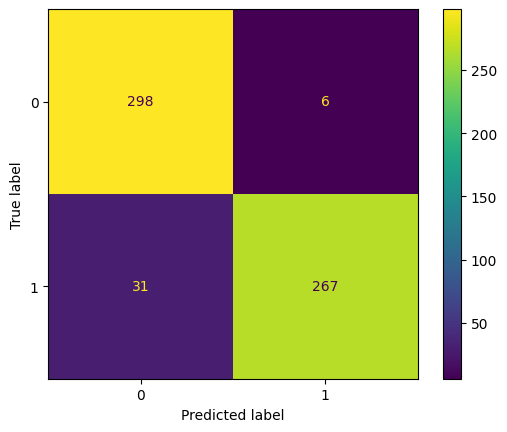

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here?
knn = KNeighborsClassifier(n_neighbors = 7)
knn.fit(transformed_X_train, y_train)

y_pred = knn.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % knn.score(transformed_X_train, y_train))
print("Test score: %f" % knn.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
grid_params = { 'n_neighbors' : [5,7,9,11,13,15],
               'weights' : ['uniform','distance'],
               'metric' : ['minkowski','euclidean','manhattan']}

gs = GridSearchCV(KNeighborsClassifier(), grid_params, verbose = 1, cv=3, n_jobs = -1)

g_res = gs.fit(transformed_X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
0.9438700377645151
{'metric': 'manhattan', 'n_neighbors': 7, 'weights': 'distance'}


              precision    recall  f1-score   support

           0       0.97      0.96      0.97       304
           1       0.96      0.97      0.97       298

    accuracy                           0.97       602
   macro avg       0.97      0.97      0.97       602
weighted avg       0.97      0.97      0.97       602

Train score: 1.000000
Test score: 0.965116
Kappa score: 0.930237


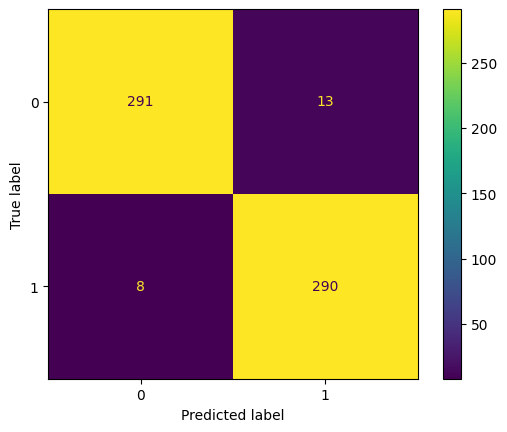

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here?
knn = KNeighborsClassifier(n_neighbors = 7, metric = 'manhattan', weights = 'distance')
knn.fit(transformed_X_train, y_train)

y_pred = knn.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % knn.score(transformed_X_train, y_train))
print("Test score: %f" % knn.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## Decision tree hog

              precision    recall  f1-score   support

           0       0.88      0.87      0.87       304
           1       0.86      0.88      0.87       298

    accuracy                           0.87       602
   macro avg       0.87      0.87      0.87       602
weighted avg       0.87      0.87      0.87       602

Train score: 1.000000
Test score: 0.870432
Kappa score: 0.740872


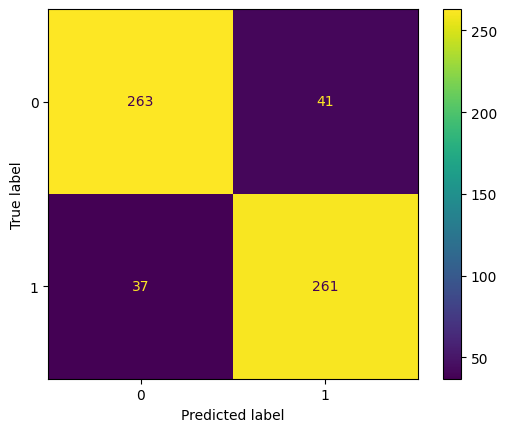

In [ ]:
# Terrible decision tree classifier - directly on pixel values
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import ExtraTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

dt = DecisionTreeClassifier(criterion='gini')
dt = dt.fit(transformed_X_train, y_train)
y_pred = dt.predict(transformed_X_test)
report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % dt.score(transformed_X_train, y_train))
print("Test score: %f" % dt.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## Random forest hog

              precision    recall  f1-score   support

           0       0.89      0.99      0.94       304
           1       0.98      0.88      0.93       298

    accuracy                           0.93       602
   macro avg       0.94      0.93      0.93       602
weighted avg       0.94      0.93      0.93       602

Train score: 0.977131
Test score: 0.933555
Kappa score: 0.866955


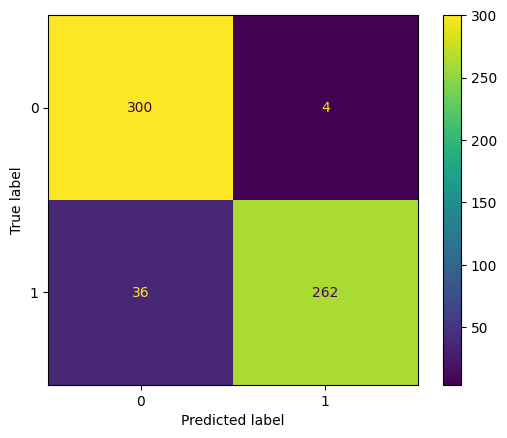

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(max_depth=7, random_state=0)

# Random forest classifier - directly on pixel values
RF = RF.fit(transformed_X_train, y_train)

y_pred = RF.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()
print("Train score: %f" % RF.score(transformed_X_train, y_train))
print("Test score: %f" % RF.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
from sklearn.ensemble import RandomForestClassifier

grid_params = {
    'max_features': ['sqrt'],
    'n_estimators': [10],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [12, 15, 20],
    'random_state': [0],
    'n_jobs' : [-1]
}

gs = GridSearchCV(RandomForestClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 9 candidates, totalling 18 fits


/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


0.9106016849169367
{'criterion': 'entropy', 'max_depth': 12, 'max_features': 'sqrt', 'n_estimators': 10, 'n_jobs': -1, 'random_state': 0}


              precision    recall  f1-score   support

           0       0.92      0.99      0.95       304
           1       0.99      0.91      0.95       298

    accuracy                           0.95       602
   macro avg       0.95      0.95      0.95       602
weighted avg       0.95      0.95      0.95       602

Train score: 1.000000
Test score: 0.950166
Kappa score: 0.900243


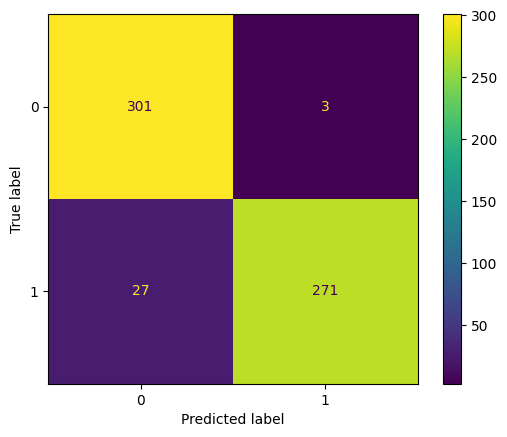

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(max_depth=12, random_state=0, criterion = 'entropy', n_estimators = 300)

# Random forest classifier - directly on pixel values
RF = RF.fit(transformed_X_train, y_train)

y_pred = RF.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()
print("Train score: %f" % RF.score(transformed_X_train, y_train))
print("Test score: %f" % RF.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## SGDClassifier hog

              precision    recall  f1-score   support

           0       0.98      0.96      0.97       304
           1       0.96      0.98      0.97       298

    accuracy                           0.97       602
   macro avg       0.97      0.97      0.97       602
weighted avg       0.97      0.97      0.97       602

Train score: 1.000000
Test score: 0.970100
Kappa score: 0.940205


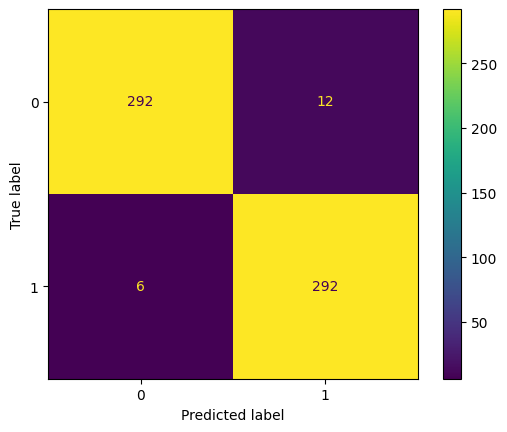

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(loss="modified_huber", max_iter=1000, eta0=1, learning_rate="constant", penalty=None)

# Train the model
sgd.fit(transformed_X_train, y_train)

# Make predictions
y_pred = sgd.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % sgd.score(transformed_X_train, y_train))
print("Test score: %f" % sgd.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
from sklearn.linear_model import SGDClassifier

grid_params = {
    'loss' : ["modified_huber"],
    'alpha' : [0.0001,0.001, 0.01, 0.1, 0.2],
    'learning_rate' : ["constant"],
    'penalty' : ["l2", "l1", None],
    'n_jobs' : [-1]
}

gs = GridSearchCV(SGDClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(transformed_X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 24 candidates, totalling 48 fits
0.9463584521779301
{'alpha': 0.01, 'loss': 'modified_huber', 'n_jobs': -1, 'penalty': 'l2'}


              precision    recall  f1-score   support

           0       0.98      0.97      0.97       304
           1       0.97      0.98      0.97       298

    accuracy                           0.97       602
   macro avg       0.97      0.97      0.97       602
weighted avg       0.97      0.97      0.97       602

Train score: 1.000000
Test score: 0.971761
Kappa score: 0.943522


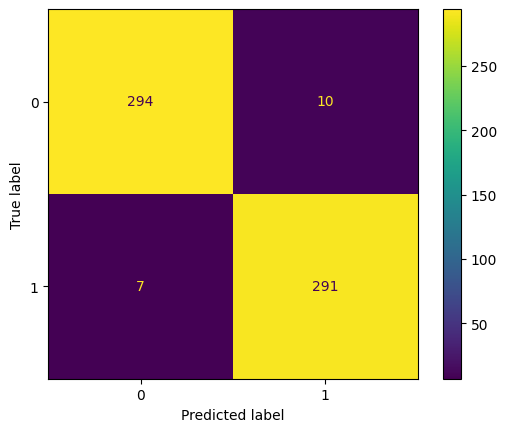

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(loss="modified_huber", max_iter=2000, eta0=1, learning_rate="constant", penalty=None)

# Train the model
sgd.fit(transformed_X_train, y_train)

# Make predictions
y_pred = sgd.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % sgd.score(transformed_X_train, y_train))
print("Test score: %f" % sgd.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## MLP hog

              precision    recall  f1-score   support

           0       0.98      0.96      0.97       304
           1       0.96      0.98      0.97       298

    accuracy                           0.97       602
   macro avg       0.97      0.97      0.97       602
weighted avg       0.97      0.97      0.97       602

Train score: 1.000000
Test score: 0.971761
Kappa score: 0.943525


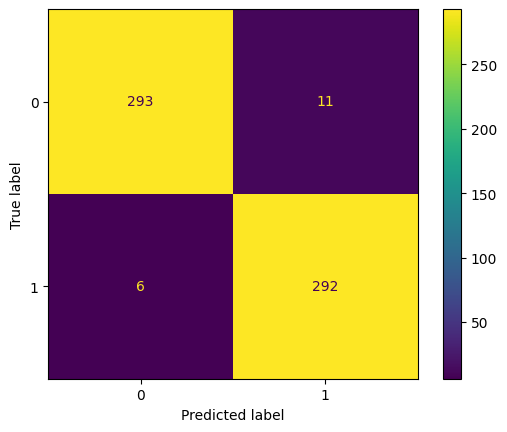

In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
clf = MLPClassifier(random_state=0, max_iter=2000, hidden_layer_sizes=(100,), activation='relu', solver='adam')
clf.fit(transformed_X_train, y_train)

# Make predictions
y_pred = clf.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % clf.score(transformed_X_train, y_train))
print("Test score: %f" % clf.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
grid_params = {
    'hidden_layer_sizes': [(50,50,50), (50,100,50), (100,)],
    'activation': ['tanh', 'relu'],
    'solver': ['sgd', 'adam'],
    'alpha': [0.0001, 0.05],
    'learning_rate': ['constant','adaptive'],
    'max_iter' : [5]
}

gs = GridSearchCV(MLPClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(transformed_X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 48 candidates, totalling 96 fits


/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


0.9413685005456409
{'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (50, 50, 50), 'learning_rate': 'adaptive', 'max_iter': 5, 'solver': 'adam'}


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5) reached and the optimization hasn't converged yet.
  warnings.warn(


              precision    recall  f1-score   support

           0       0.98      0.97      0.97       304
           1       0.97      0.98      0.97       298

    accuracy                           0.97       602
   macro avg       0.97      0.97      0.97       602
weighted avg       0.97      0.97      0.97       602

Train score: 1.000000
Test score: 0.973422
Kappa score: 0.946846


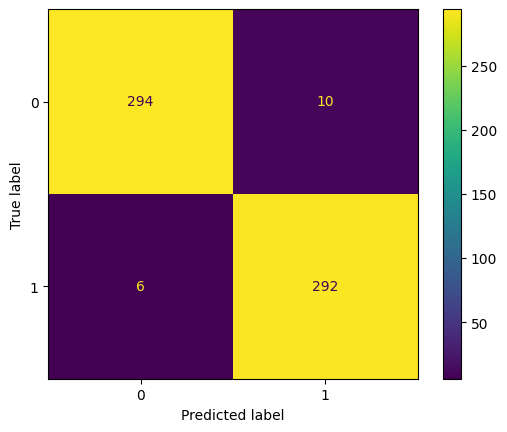

In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
clf = MLPClassifier(random_state=0, max_iter=2000, activation = 'relu', hidden_layer_sizes = (50,50,50), learning_rate = 'adaptive', solver = 'adam')
clf.fit(transformed_X_train, y_train)

# Make predictions
y_pred = clf.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % clf.score(transformed_X_train, y_train))
print("Test score: %f" % clf.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## CNN hog

In [ ]:
model = tf.keras.Sequential([
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])

In [ ]:
model.compile(
  optimizer="adam",
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])

In [ ]:
epochs = 15

history = model.fit(
  transformed_X_train2, y_train,
  validation_data=(transformed_X_test, y_test), shuffle=True,
  epochs=epochs, batch_size=32
)

Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 49s 630ms/step - accuracy: 0.7868 - loss: 2.2703 - val_accuracy: 0.9203 - val_loss: 0.2036
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 71s 484ms/step - accuracy: 0.9295 - loss: 0.1762 - val_accuracy: 0.9236 - val_loss: 0.2034
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 37s 490ms/step - accuracy: 0.9555 - loss: 0.1199 - val_accuracy: 0.9385 - val_loss: 0.1940
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 495ms/step - accuracy: 0.9763 - loss: 0.0720 - val_accuracy: 0.9385 - val_loss: 0.2161
Epoch 5/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 489ms/step - accuracy: 0.9755 - loss: 0.0654 - val_accuracy: 0.9452 - val_loss: 0.1839
Epoch 6/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 492ms/step - accuracy: 0.9905 - loss: 0.0291 - val_accuracy: 0.9369 - val_loss: 0.1995
Epoch 7/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 46s 563ms/step - accuracy: 0.9911 - loss: 0.0351 - val_accuracy: 0.9502 - val_loss: 0.1650
Epoch 8/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 78s 507ms/step - accuracy: 0.9942 - loss: 0.0273 - val_accu

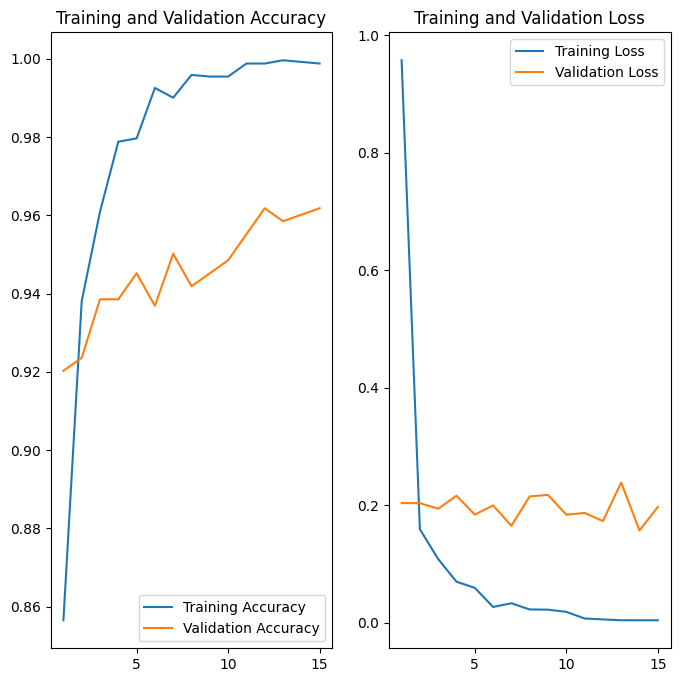

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(transformed_X_test2, y_test, verbose=2)

19/19 - 2s - 110ms/step - accuracy: 0.9618 - loss: 0.1969


In [ ]:
# Function to create model, required for KerasClassifier

def create_model(optimizer='adam'):
  # create model
  model = tf.keras.Sequential()
  model.add(tf.keras.layers.Conv2D(32, 5, activation='relu'))
  model.add(tf.keras.layers.MaxPooling2D())
  model.add(tf.keras.layers.Flatten())
  model.add(tf.keras.layers.Dense(128, activation='relu'))
  model.add(tf.keras.layers.Dense(1, activation='sigmoid'))

	# Compile mode
  model.compile(
  #optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
  optimizer=optimizer,
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])
  return model

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=6, verbose=1)
mc = tf.keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

# create model
model = KerasClassifier(model=create_model, verbose=0)

# define the grid search parameters
batch_size = [10, 20, 40, 60, 80, 100]
epochs = [15]
optimizer = ['SGD', 'RMSprop', 'Adagrad', 'Adadelta', 'Adam', 'Adamax', 'Nadam']
param_grid = dict(batch_size=batch_size, epochs=epochs, model__optimizer=optimizer)

grid = GridSearchCV(estimator=model, param_grid=param_grid, n_jobs=-1, cv=3)
grid_result = grid.fit(transformed_X_train, y_train)
# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

ValueError: 
All the 126 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.10/dist-packages/scikeras/wrappers.py", line 1501, in fit
    super().fit(X=X, y=y, sample_weight=sample_weight, **kwargs)
  File "/usr/local/lib/python3.10/dist-packages/scikeras/wrappers.py", line 770, in fit
    self._fit(
  File "/usr/local/lib/python3.10/dist-packages/scikeras/wrappers.py", line 936, in _fit
    self._check_model_compatibility(y)
  File "/usr/local/lib/python3.10/dist-packages/scikeras/wrappers.py", line 559, in _check_mode

## CNN hog modified

In [ ]:
# clear session
tf.keras.backend.clear_session(
    free_memory=True
)

In [ ]:
transformed_X_train2 = []
transformed_X_test2 = []

for img in transformed_X_train:
  img = np.reshape(img,(128, 128, 1))
  transformed_X_train2.append(img)

for img in transformed_X_test:
  img = np.reshape(img,(128, 128, 1))
  transformed_X_test2.append(img)

transformed_X_train2 = np.array(transformed_X_train2)
transformed_X_test2 = np.array(transformed_X_test2)

img = []

print(transformed_X_train2.shape)
print(transformed_X_test2.shape)

(2405, 128, 128, 1)
(602, 128, 128, 1)


In [ ]:
model = tf.keras.Sequential([
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Flatten(),
  #tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(256, activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])
model.compile(
  optimizer="adam",
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=6, verbose=1)
mc = tf.keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

epochs = 15

history = model.fit(
  transformed_X_train2, y_train,
  validation_data=(transformed_X_test2, y_test), shuffle=True,
  epochs=epochs, batch_size=32, callbacks = [es, mc]
)


Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 575ms/step - accuracy: 0.8114 - loss: 0.4019
Epoch 1: val_loss improved from inf to 0.13677, saving model to best_model.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 60s 766ms/step - accuracy: 0.8123 - loss: 0.4003 - val_accuracy: 0.9551 - val_loss: 0.1368
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 592ms/step - accuracy: 0.9659 - loss: 0.1079
Epoch 2: val_loss improved from 0.13677 to 0.09957, saving model to best_model.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 55s 723ms/step - accuracy: 0.9659 - loss: 0.1078 - val_accuracy: 0.9684 - val_loss: 0.0996
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 600ms/step - accuracy: 0.9800 - loss: 0.0589
Epoch 3: val_loss did not improve from 0.09957
76/76 ━━━━━━━━━━━━━━━━━━━━ 48s 626ms/step - accuracy: 0.9801 - loss: 0.0589 - val_accuracy: 0.9701 - val_loss: 0.1007
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 585ms/step - accuracy: 0.9909 - loss: 0.0364
Epoch 4: val_loss did not improve from 0.09957
76/76 ━━━━━━━━━━━━━━━━━━━━ 47s 621ms/step 

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 124, 124, 32)        │             832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 62, 62, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 123008)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │      31,490,304 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 94,474,181 (360.39 MB)

 Trainable params: 31,491,393 (120.13 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 62,982,788 (240.26 MB)

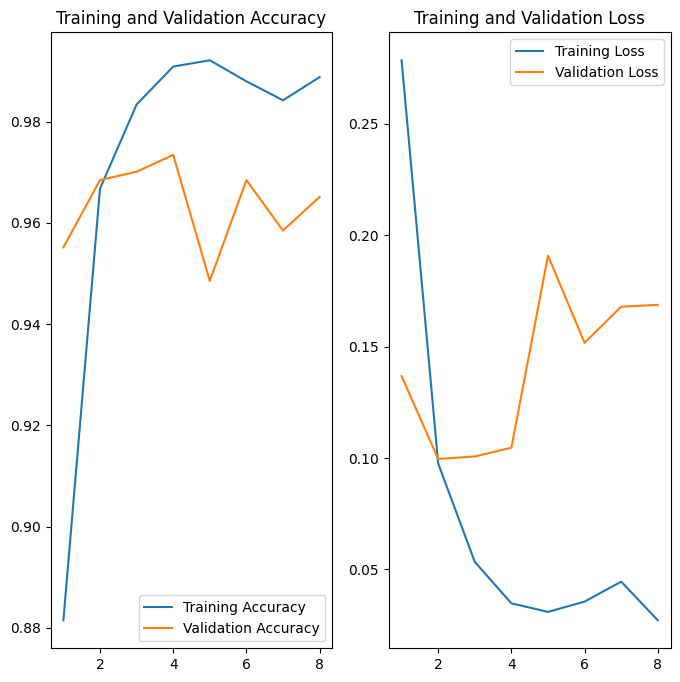

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(transformed_X_test2, y_test, verbose=2)

19/19 - 2s - 101ms/step - accuracy: 0.9651 - loss: 0.1687


# Grey images

In [ ]:
def augment(image):
  image = tf.image.random_brightness(image, max_delta=0.5)
  image = tf.image.random_contrast(image, lower=0.5, upper=1.5)
  image = tf.image.random_flip_left_right(image)
  return image

SIZE = 128  #Resize images

#Capture training data and labels into respective lists
images = []
labels = []

#Folder to put images that has weird sizes.
data_error_dir = "/content/drive/MyDrive/ML_IPData7/imgerrors"
! mkdir $data_error_dir
data_errsizesushi_dir = "/content/drive/MyDrive/ML_IPData7/imgsizeerrors"
! mkdir $data_errsizesushi_dir
data_errsizesword_dir = "/content/drive/MyDrive/ML_IPData7/imgsizeerrorssword"
! mkdir $data_errsizesword_dir

for directory_path in glob.glob("/content/drive/MyDrive/ML_IPData7/Datasets/*"):
    label = directory_path.split("/")[-1]
    print(label)
    for img_path in glob.glob(os.path.join(directory_path, "*.jpg")):
        img = io.imread(img_path)

        # Move all images with weird sizes to another folder
        if (len(img.shape) < 3):
          shutil.move(img_path, data_error_dir)
          print(img.shape)
          continue
        # Move all images with weird sizes to another folder
        elif img.shape[0] < 128 or img.shape[1] < 128:
          shutil.move(img_path, data_errsizesword_dir)
          continue
        else:
          img = skimage.color.rgb2gray(img)
          img = resize(img, (SIZE, SIZE, 1))

        labels.append(label)
        images.append(img)

        if label == "Sword":
          for i in range(0,3):
            img = augment(img)
            images.append(img)
            labels.append(label)

img = []

mkdir: cannot create directory ‘/content/drive/MyDrive/ML_IPData7/imgerrors’: File exists
mkdir: cannot create directory ‘/content/drive/MyDrive/ML_IPData7/imgsizeerrors’: File exists
mkdir: cannot create directory ‘/content/drive/MyDrive/ML_IPData7/imgsizeerrorssword’: File exists


NameError: name 'glob' is not defined

In [ ]:
images = np.array(images)
labels = np.array(labels)
type(labels)

from sklearn.preprocessing import OneHotEncoder, LabelEncoder
labelencoder = LabelEncoder()

labelencoder.fit(labels)
enc_labels = labelencoder.transform(labels)

print(enc_labels[0])
print(labels[0])

NameError: name 'np' is not defined

In [ ]:
flattened_images = []

for img in images:
  img = img.reshape((img.shape[0] * img.shape[1] * img.shape[2]))
  flattened_images.append(img)

images = []
labels = []

flattened_images = np.array(flattened_images)
print(flattened_images.shape)

X_train, X_test, y_train, y_test = train_test_split (flattened_images, enc_labels, test_size = 0.2, random_state = 1)


# Your code to Print the shapes of the X_train, X_test, y_train, y_test

print (X_train.shape)
print (X_test.shape)
print (y_train.shape)
print (y_test.shape)


NameError: name 'np' is not defined

Text(0, 0.5, 'Cumulated variance')

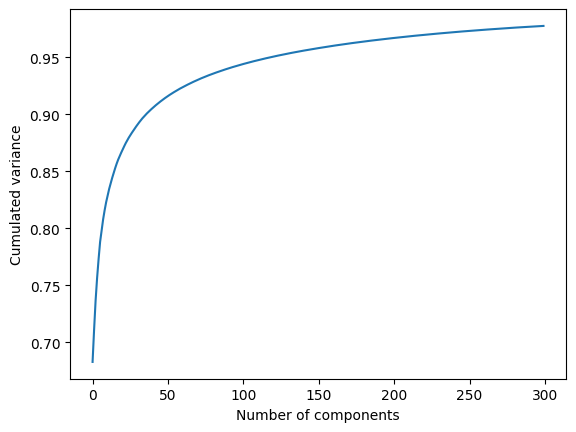

In [ ]:
# data is centered by PCA

# How many components to choose?
pca_tr = PCA(n_components=300)
# Why apply PCA to the training data and not to all data?
pca_tr.fit(X_train)
plt.plot(np.cumsum(pca_tr.explained_variance_ratio_))
plt.xlabel("Number of components")
plt.ylabel("Cumulated variance")

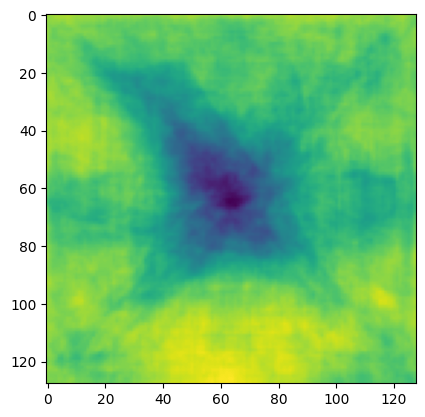

In [ ]:
test = pca_tr.components_[0].reshape(SIZE, SIZE*1)
plt.imshow(test)
test = []

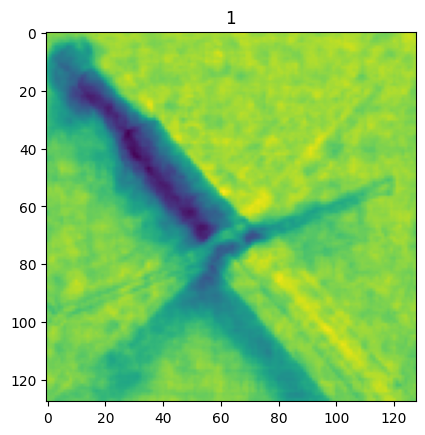

In [ ]:
# Reconstruct one image from the first 300 bases
projims = pca_tr.transform(X_test)
k = 10
res = np.zeros((SIZE*SIZE*1))
for i in range(300):
  res += pca_tr.components_[i].dot(projims[k,i])

plt.imshow(res.reshape(SIZE, SIZE*1))
plt.title(y_test[k])

projims = []
res = []

## KNN with PCA

              precision    recall  f1-score   support

           0       0.90      0.62      0.74       304
           1       0.71      0.93      0.80       298

    accuracy                           0.78       602
   macro avg       0.81      0.78      0.77       602
weighted avg       0.81      0.78      0.77       602

Train score: 0.812474
Test score: 0.775748
Kappa score: 0.552857


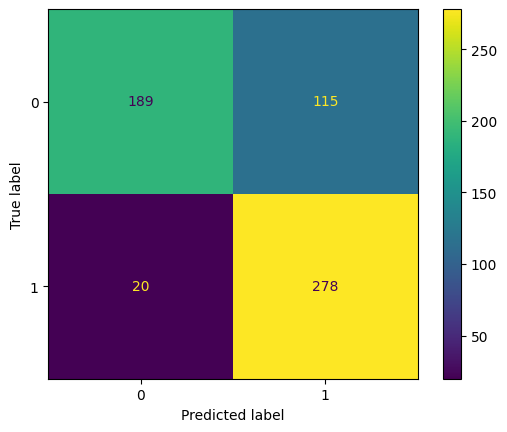

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here?
knn = KNeighborsClassifier(n_neighbors = 7)
knn.fit(pca_tr.transform(X_train), y_train)

y_pred = knn.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % knn.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % knn.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
grid_params = { 'n_neighbors' : [5,7,9,11,13,15],
               'weights' : ['uniform','distance'],
               'metric' : ['minkowski','euclidean','manhattan']}

gs = GridSearchCV(KNeighborsClassifier(), grid_params, verbose = 1, cv=3, n_jobs = -1)

g_res = gs.fit(pca_tr.transform(X_train), y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
0.7625785722958521
{'metric': 'minkowski', 'n_neighbors': 5, 'weights': 'distance'}


              precision    recall  f1-score   support

           0       0.90      0.62      0.73       304
           1       0.71      0.93      0.80       298

    accuracy                           0.77       602
   macro avg       0.80      0.78      0.77       602
weighted avg       0.81      0.77      0.77       602

Train score: 1.000000
Test score: 0.774086
Kappa score: 0.549560


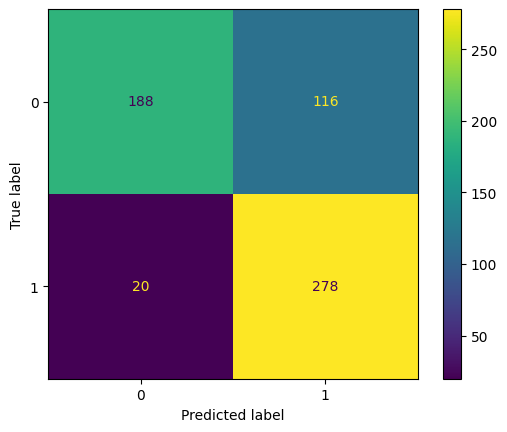

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here?
knn = KNeighborsClassifier(n_neighbors = 5, weights = 'distance')
knn.fit(pca_tr.transform(X_train), y_train)

y_pred = knn.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % knn.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % knn.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## KNN without PCA

              precision    recall  f1-score   support

           0       0.90      0.57      0.69       304
           1       0.68      0.94      0.79       298

    accuracy                           0.75       602
   macro avg       0.79      0.75      0.74       602
weighted avg       0.79      0.75      0.74       602

Train score: 0.785863
Test score: 0.749169
Kappa score: 0.500159


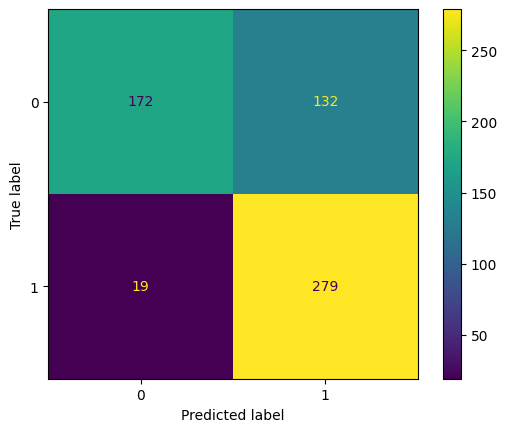

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here?
knn = KNeighborsClassifier(n_neighbors = 7)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % knn.score(X_train, y_train))
print("Test score: %f" % knn.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
grid_params = { 'n_neighbors' : [5,7,9,11,13,15],
               'weights' : ['uniform','distance'],
               'metric' : ['minkowski','euclidean','manhattan']}

gs = GridSearchCV(KNeighborsClassifier(), grid_params, verbose = 1, cv=3, n_jobs = -1)

g_res = gs.fit(X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
0.7629884921487377
{'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}


              precision    recall  f1-score   support

           0       0.96      0.65      0.77       304
           1       0.73      0.97      0.83       298

    accuracy                           0.81       602
   macro avg       0.84      0.81      0.80       602
weighted avg       0.85      0.81      0.80       602

Train score: 1.000000
Test score: 0.808970
Kappa score: 0.619126


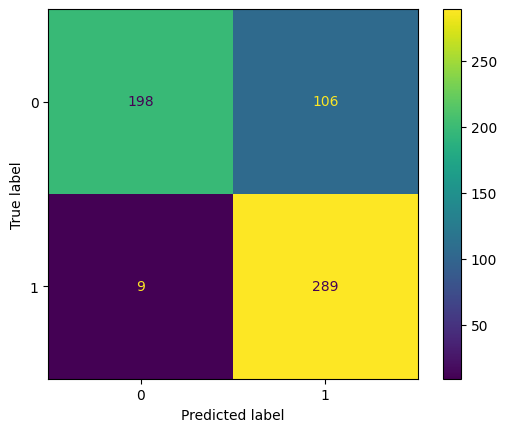

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here?
knn = KNeighborsClassifier(metric = 'manhattan', n_neighbors = 5, weights = 'distance')
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % knn.score(X_train, y_train))
print("Test score: %f" % knn.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## Decision tree with PCA

              precision    recall  f1-score   support

           0       0.84      0.76      0.79       304
           1       0.77      0.85      0.81       298

    accuracy                           0.80       602
   macro avg       0.81      0.80      0.80       602
weighted avg       0.81      0.80      0.80       602

Train score: 1.000000
Test score: 0.802326


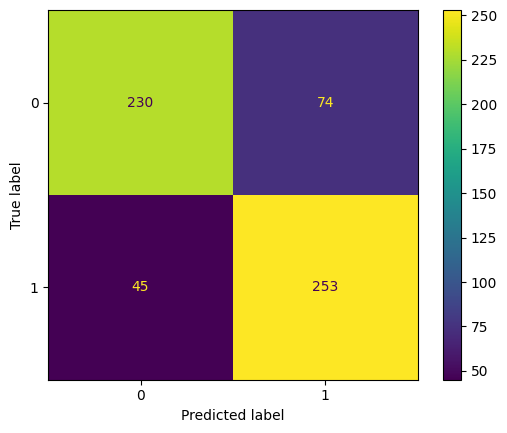

In [ ]:
# Terrible decision tree classifier - directly on pixel values
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import ExtraTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

dt = DecisionTreeClassifier(criterion='gini')
dt = dt.fit(pca_tr.transform(X_train), y_train)
y_pred = dt.predict(pca_tr.transform(X_test))
report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % dt.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % dt.score(pca_tr.transform(X_test), y_test))

## Decision tree without PCA

              precision    recall  f1-score   support

           0       0.83      0.82      0.82       304
           1       0.82      0.83      0.82       298

    accuracy                           0.82       602
   macro avg       0.82      0.82      0.82       602
weighted avg       0.82      0.82      0.82       602

Train score: 1.000000
Test score: 0.822259


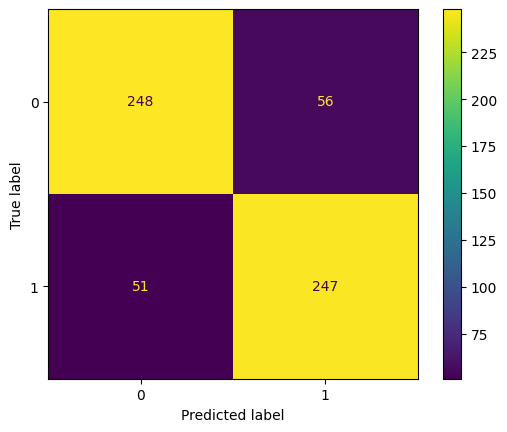

In [ ]:
# Terrible decision tree classifier - directly on pixel values
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import ExtraTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

dt = DecisionTreeClassifier(criterion='gini')
dt = dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)
report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % dt.score(X_train, y_train))
print("Test score: %f" % dt.score(X_test, y_test))

## Random forest with PCA

              precision    recall  f1-score   support

           0       0.87      0.95      0.91       304
           1       0.94      0.86      0.90       298

    accuracy                           0.90       602
   macro avg       0.91      0.90      0.90       602
weighted avg       0.91      0.90      0.90       602

Train score: 0.981705
Test score: 0.901993
Kappa score: 0.803792


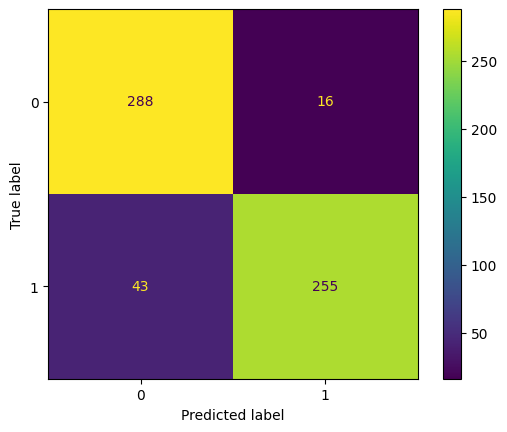

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(max_depth=7, random_state=0)

# Random forest classifier - directly on pixel values
RF = RF.fit(pca_tr.transform(X_train), y_train)

y_pred = RF.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()
print("Train score: %f" % RF.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % RF.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
from sklearn.ensemble import RandomForestClassifier

grid_params = {
    'max_features': ['sqrt'],
    'n_estimators': [10],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [12, 15, 20],
    'random_state': [0],
    'n_jobs' : [-1]
}

gs = GridSearchCV(RandomForestClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(pca_tr.transform(X_train), y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 9 candidates, totalling 18 fits


/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


0.7879379476986956
{'criterion': 'entropy', 'max_depth': 15, 'max_features': 'sqrt', 'n_estimators': 10, 'n_jobs': -1, 'random_state': 0}


              precision    recall  f1-score   support

           0       0.92      0.95      0.93       304
           1       0.95      0.91      0.93       298

    accuracy                           0.93       602
   macro avg       0.93      0.93      0.93       602
weighted avg       0.93      0.93      0.93       602

Train score: 0.999584
Test score: 0.931894
Kappa score: 0.863724


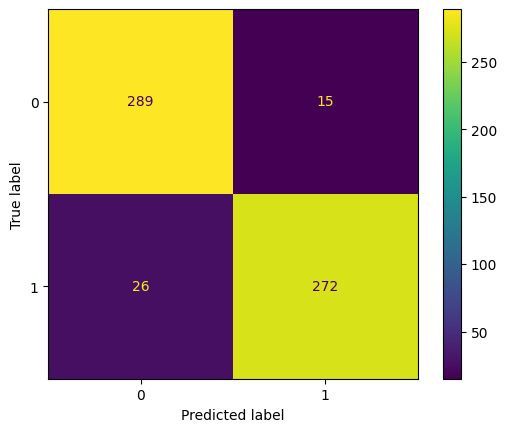

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(max_depth=15, random_state=0, criterion = 'entropy', n_estimators=300, n_jobs = -1)

# Random forest classifier - directly on pixel values
RF = RF.fit(pca_tr.transform(X_train), y_train)

y_pred = RF.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()
print("Train score: %f" % RF.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % RF.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## Random forest without PCA

              precision    recall  f1-score   support

           0       0.77      0.98      0.87       304
           1       0.98      0.70      0.82       298

    accuracy                           0.85       602
   macro avg       0.87      0.84      0.84       602
weighted avg       0.87      0.85      0.84       602

Train score: 0.879002
Test score: 0.845515
Kappa score: 0.690148


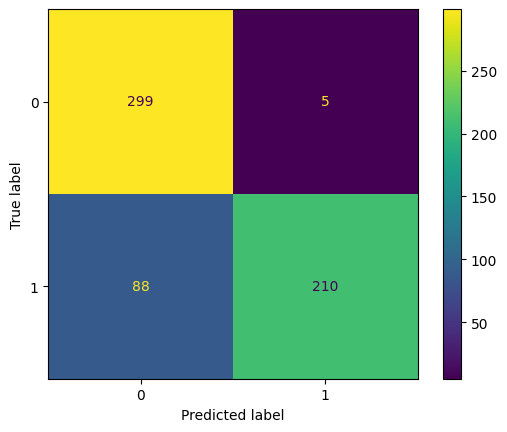

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(max_depth=7, random_state=0)

# Random forest classifier - directly on pixel values
RF = RF.fit(X_train, y_train)

y_pred = RF.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()
print("Train score: %f" % RF.score(X_train, y_train))
print("Test score: %f" % RF.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
from sklearn.ensemble import RandomForestClassifier

grid_params = {
    'max_features': ['sqrt'],
    'n_estimators': [10],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [12, 15, 20],
    'random_state': [0],
    'n_jobs' : [-1]
}

gs = GridSearchCV(RandomForestClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 24 candidates, totalling 48 fits


/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


0.8640330676359573
{'criterion': 'entropy', 'max_depth': 14, 'max_features': 'sqrt', 'n_estimators': 10, 'n_jobs': -1, 'random_state': 0}


              precision    recall  f1-score   support

           0       0.86      0.97      0.91       304
           1       0.97      0.84      0.90       298

    accuracy                           0.91       602
   macro avg       0.92      0.91      0.91       602
weighted avg       0.92      0.91      0.91       602

Train score: 0.998753
Test score: 0.908638
Kappa score: 0.817021


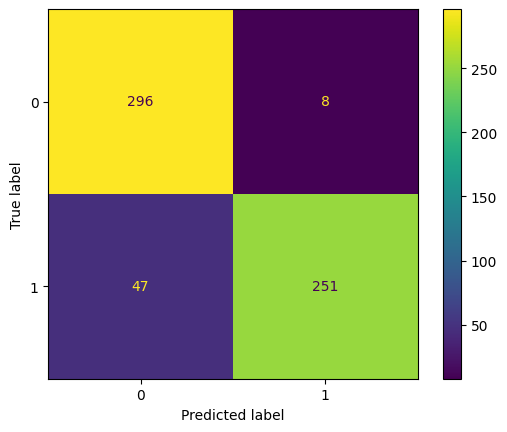

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(max_depth=14, random_state=0, criterion = 'entropy', n_estimators=300, n_jobs = -1)

# Random forest classifier - directly on pixel values
RF = RF.fit(X_train, y_train)

y_pred = RF.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()
print("Train score: %f" % RF.score(X_train, y_train))
print("Test score: %f" % RF.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## SGDClassifier with PCA

              precision    recall  f1-score   support

           0       0.71      0.72      0.71       304
           1       0.71      0.70      0.70       298

    accuracy                           0.71       602
   macro avg       0.71      0.71      0.71       602
weighted avg       0.71      0.71      0.71       602

Train score: 0.771726
Test score: 0.709302
Kappa score: 0.418451


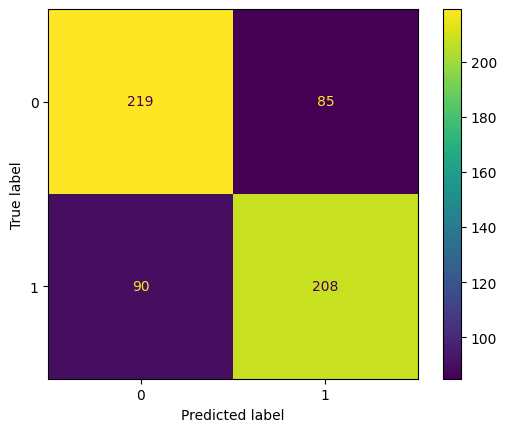

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(loss="modified_huber", max_iter=1000, eta0=1, learning_rate="constant", penalty=None)

# Train the model
sgd.fit(pca_tr.transform(X_train), y_train)

# Make predictions
y_pred = sgd.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % sgd.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % sgd.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))


### Cross validation

In [ ]:
from sklearn.linear_model import SGDClassifier

grid_params = {
    'loss' : ["modified_huber"],
    'alpha' : [0.0001,0.001, 0.01, 0.1, 0.2],
    'learning_rate' : ["constant", "optimal"],
    'penalty' : ["l2", "l1", None],
    'n_jobs' : [-1]
}

gs = GridSearchCV(SGDClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(pca_tr.transform(X_train), y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 30 candidates, totalling 60 fits


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py:540: FitFailedWarning: 
30 fits failed out of a total of 60.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
30 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/base.py", line 1473, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_stochastic_gradient.py", line 936, in fit
    self._more_validate_params()
  File "/usr/local/lib/python3.10

0.7185004764848832
{'alpha': 0.2, 'learning_rate': 'optimal', 'loss': 'modified_huber', 'n_jobs': -1, 'penalty': 'l2'}


              precision    recall  f1-score   support

           0       0.73      0.66      0.70       304
           1       0.69      0.76      0.72       298

    accuracy                           0.71       602
   macro avg       0.71      0.71      0.71       602
weighted avg       0.71      0.71      0.71       602

Train score: 0.807900
Test score: 0.709302
Kappa score: 0.419105


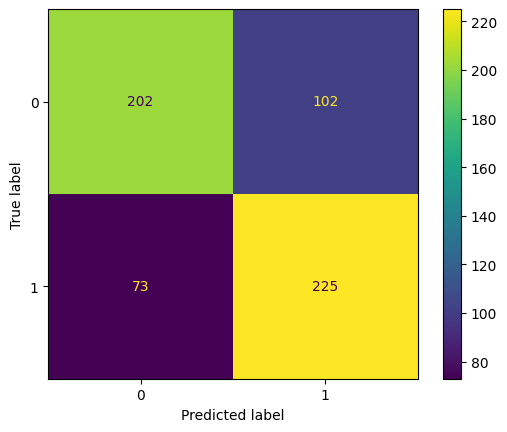

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(loss="modified_huber", max_iter=2000, eta0=1, learning_rate="optimal", penalty=None, n_jobs = -1)

# Train the model
sgd.fit(pca_tr.transform(X_train), y_train)

# Make predictions
y_pred = sgd.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % sgd.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % sgd.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))


## SGDClassifier without PCA

              precision    recall  f1-score   support

           0       0.56      0.96      0.71       304
           1       0.84      0.23      0.36       298

    accuracy                           0.60       602
   macro avg       0.70      0.59      0.53       602
weighted avg       0.70      0.60      0.54       602

Train score: 0.632432
Test score: 0.598007
Kappa score: 0.190141


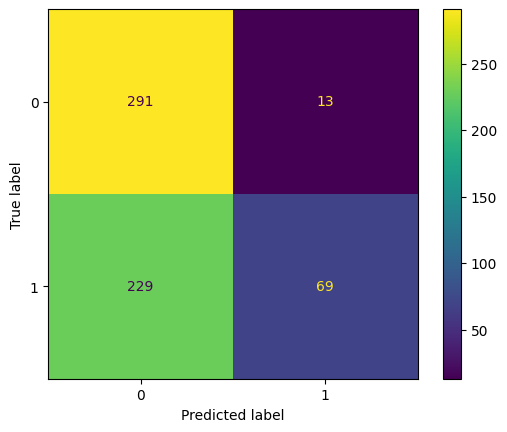

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(loss="modified_huber", max_iter=1000, eta0=1, learning_rate="constant", penalty=None)

# Train the model
sgd.fit(X_train, y_train)

# Make predictions
y_pred = sgd.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % sgd.score(X_train, y_train))1
print("Test score: %f" % sgd.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
from sklearn.linear_model import SGDClassifier

grid_params = {
    'loss' : ["modified_huber"],
    'alpha' : [0.0001,0.001, 0.01, 0.1, 0.2],
    'learning_rate' : ["constant", "optimal"],
    'penalty' : ["l2", "l1", None],
    'n_jobs' : [-1]
}

gs = GridSearchCV(SGDClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 30 candidates, totalling 60 fits


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py:540: FitFailedWarning: 
30 fits failed out of a total of 60.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
30 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/base.py", line 1473, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_stochastic_gradient.py", line 936, in fit
    self._more_validate_params()
  File "/usr/local/lib/python3.10

0.7405408414626219
{'alpha': 0.001, 'learning_rate': 'optimal', 'loss': 'modified_huber', 'n_jobs': -1, 'penalty': 'l2'}


              precision    recall  f1-score   support

           0       0.72      0.93      0.81       304
           1       0.90      0.63      0.74       298

    accuracy                           0.78       602
   macro avg       0.81      0.78      0.78       602
weighted avg       0.81      0.78      0.78       602

Train score: 0.859459
Test score: 0.782392
Kappa score: 0.563483


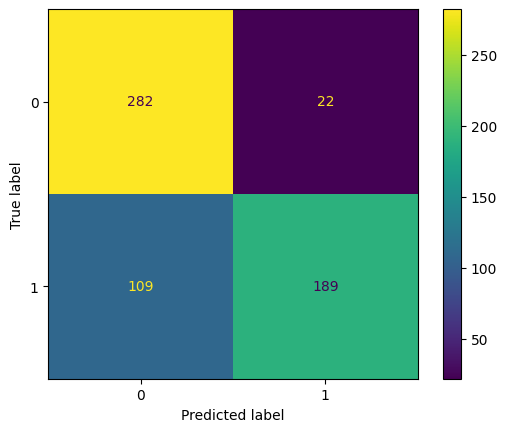

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(loss="modified_huber", alpha = 0.001, max_iter=2000, n_jobs = -1, learning_rate="optimal", penalty='l2')

# Train the model
sgd.fit(X_train, y_train)

# Make predictions
y_pred = sgd.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % sgd.score(X_train, y_train))
print("Test score: %f" % sgd.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## MLP with PCA

              precision    recall  f1-score   support

           0       0.93      0.91      0.92       304
           1       0.91      0.93      0.92       298

    accuracy                           0.92       602
   macro avg       0.92      0.92      0.92       602
weighted avg       0.92      0.92      0.92       602

Train score: 1.000000
Test score: 0.921927
Kappa score: 0.843864


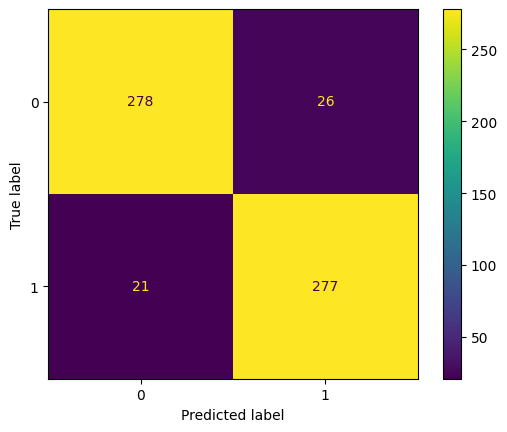

In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
clf = MLPClassifier(random_state=0, max_iter=2000, hidden_layer_sizes=(100,), activation='relu', solver='adam')
clf.fit(pca_tr.transform(X_train), y_train)

# Make predictions
y_pred = clf.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % clf.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % clf.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
grid_params = {
    'hidden_layer_sizes': [(50,50,50), (50,100,50), (100,)],
    'activation': ['tanh', 'relu'],
    'solver': ['sgd', 'adam'],
    'alpha': [0.0001, 0.05],
    'learning_rate': ['constant','adaptive'],
    'max_iter' : [100]
}

gs = GridSearchCV(MLPClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(pca_tr.transform(X_train), y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 48 candidates, totalling 96 fits
0.8806668160436402
{'activation': 'relu', 'alpha': 0.05, 'hidden_layer_sizes': (50, 100, 50), 'learning_rate': 'constant', 'max_iter': 100, 'solver': 'adam'}


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


              precision    recall  f1-score   support

           0       0.94      0.90      0.92       304
           1       0.90      0.94      0.92       298

    accuracy                           0.92       602
   macro avg       0.92      0.92      0.92       602
weighted avg       0.92      0.92      0.92       602

Train score: 1.000000
Test score: 0.921927
Kappa score: 0.843906


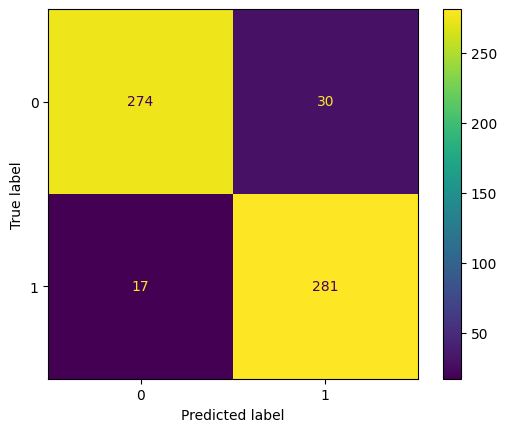

In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
clf = MLPClassifier(alpha = 0.05, max_iter=2000, hidden_layer_sizes=(100,), learning_rate = 'constant', activation='relu', solver='adam')
clf.fit(pca_tr.transform(X_train), y_train)

# Make predictions
y_pred = clf.predict(pca_tr.transform(X_test))

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % clf.score(pca_tr.transform(X_train), y_train))
print("Test score: %f" % clf.score(pca_tr.transform(X_test), y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## MLP without PCA

              precision    recall  f1-score   support

           0       0.78      0.46      0.58       304
           1       0.61      0.87      0.72       298

    accuracy                           0.66       602
   macro avg       0.69      0.66      0.65       602
weighted avg       0.69      0.66      0.64       602

Train score: 0.739293
Test score: 0.659468
Kappa score: 0.321677


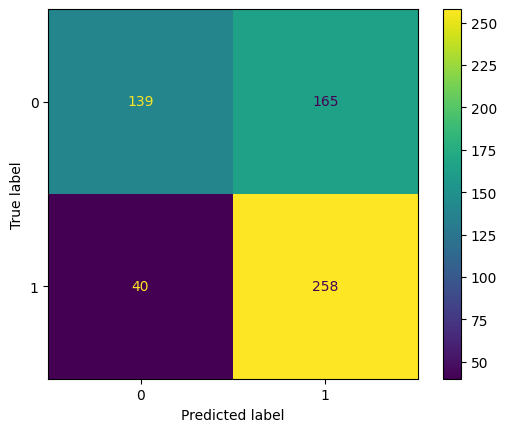

In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
clf = MLPClassifier(random_state=0, max_iter=2000, hidden_layer_sizes=(100,), activation='relu', solver='adam')
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % clf.score(X_train, y_train))
print("Test score: %f" % clf.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
grid_params = {
    'hidden_layer_sizes': [(50,50,50), (50,100,50), (100,)],
    'activation': ['tanh', 'relu'],
    'solver': ['sgd', 'adam'],
    'alpha': [0.0001, 0.05],
    'learning_rate': ['constant','adaptive'],
    'max_iter' : [2]
}

gs = GridSearchCV(MLPClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 48 candidates, totalling 96 fits


KeyboardInterrupt: 

              precision    recall  f1-score   support

           0       0.83      0.71      0.77       304
           1       0.74      0.85      0.79       298

    accuracy                           0.78       602
   macro avg       0.79      0.78      0.78       602
weighted avg       0.79      0.78      0.78       602

Train score: 0.834511
Test score: 0.782392
Kappa score: 0.565360


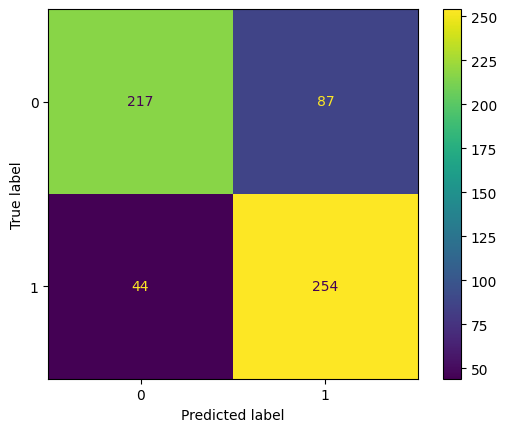

In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
clf = MLPClassifier(random_state=0, max_iter=2000, hidden_layer_sizes=(50,100,50), activation='relu', solver='adam')
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % clf.score(X_train, y_train))
print("Test score: %f" % clf.score(X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## CNN without PCA

In [ ]:
import tensorflow as tf

# clear session
tf.keras.backend.clear_session(
    free_memory=True
)

In [ ]:
transformed_X_train = []
transformed_X_test = []

for img in X_train:
  img = np.reshape(img,(128, 128, 1))
  transformed_X_train.append(img)

for img in X_test:
  img = np.reshape(img,(128, 128, 1))
  transformed_X_test.append(img)

transformed_X_train = np.array(transformed_X_train)
transformed_X_test = np.array(transformed_X_test)

img = []

print(transformed_X_train.shape)
print(transformed_X_test.shape)

(2405, 128, 128, 1)
(602, 128, 128, 1)


In [ ]:
model = tf.keras.Sequential([
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])

In [ ]:
model.compile(
  #optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
  optimizer="adam",
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])

In [ ]:
epochs = 15

history = model.fit(
  transformed_X_train, y_train,
  validation_data=(transformed_X_test, y_test), shuffle=True,
  epochs=epochs, batch_size=32
)

Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 61s 758ms/step - accuracy: 0.6125 - loss: 1.4419 - val_accuracy: 0.8522 - val_loss: 0.3435
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 82s 767ms/step - accuracy: 0.8730 - loss: 0.2985 - val_accuracy: 0.9103 - val_loss: 0.2271
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 55s 421ms/step - accuracy: 0.9205 - loss: 0.1975 - val_accuracy: 0.9252 - val_loss: 0.1909
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 47s 503ms/step - accuracy: 0.9466 - loss: 0.1411 - val_accuracy: 0.9286 - val_loss: 0.1797
Epoch 5/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 33s 432ms/step - accuracy: 0.9603 - loss: 0.0973 - val_accuracy: 0.9369 - val_loss: 0.1682
Epoch 6/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 45s 486ms/step - accuracy: 0.9834 - loss: 0.0561 - val_accuracy: 0.9485 - val_loss: 0.1507
Epoch 7/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 38s 446ms/step - accuracy: 0.9900 - loss: 0.0377 - val_accuracy: 0.9568 - val_loss: 0.1425
Epoch 8/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 449ms/step - accuracy: 0.9954 - loss: 0.0285 - val_accu

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 124, 124, 32)        │             832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 62, 62, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 123008)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      15,745,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 47,238,341 (180.20 MB)

 Trainable params: 15,746,113 (60.07 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 31,492,228 (120.13 MB)

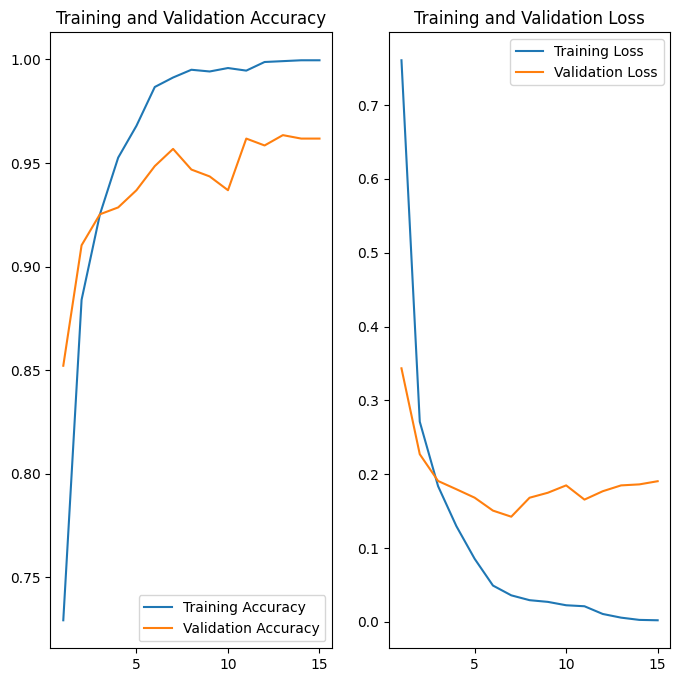

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)


plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(transformed_X_test, y_test, verbose=2)

19/19 - 2s - 88ms/step - accuracy: 0.9618 - loss: 0.1906


### Cross validation

In [ ]:
model = tf.keras.Sequential([
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Flatten(),
  #tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(256, activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])
model.compile(
  optimizer="adam",
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=6, verbose=1)
mc = tf.keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

epochs = 15

history = model.fit(
  transformed_X_train, y_train,
  validation_data=(transformed_X_test, y_test), shuffle=True,
  epochs=epochs, batch_size=32, callbacks = [es, mc]
)

Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 581ms/step - accuracy: 0.6704 - loss: 2.3052
Epoch 1: val_loss improved from inf to 0.33763, saving model to best_model.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 59s 756ms/step - accuracy: 0.6716 - loss: 2.2880 - val_accuracy: 0.8488 - val_loss: 0.3376
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 579ms/step - accuracy: 0.8725 - loss: 0.3093
Epoch 2: val_loss improved from 0.33763 to 0.28815, saving model to best_model.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 80s 726ms/step - accuracy: 0.8725 - loss: 0.3093 - val_accuracy: 0.8854 - val_loss: 0.2881
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 669ms/step - accuracy: 0.9004 - loss: 0.2382
Epoch 3: val_loss improved from 0.28815 to 0.21227, saving model to best_model.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 92s 871ms/step - accuracy: 0.9005 - loss: 0.2379 - val_accuracy: 0.9120 - val_loss: 0.2123
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 591ms/step - accuracy: 0.9429 - loss: 0.1417
Epoch 4: val_loss improved from 0.21227 to 0.19737,

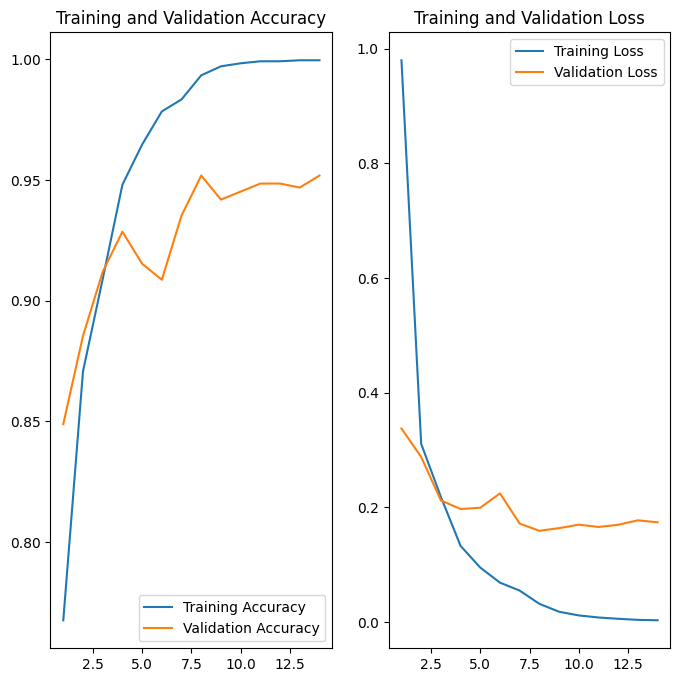

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)


plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(transformed_X_test, y_test, verbose=2)

19/19 - 2s - 131ms/step - accuracy: 0.9518 - loss: 0.1741


## CNN with PCA

In [ ]:
import tensorflow as tf

# clear session
tf.keras.backend.clear_session(
    free_memory=True
)

In [ ]:
# Reconstruct train images from the first 300 bases

projims = pca_tr.transform(X_train)
transformed_X_train = []
for k in range(0,len(projims)):
  res = np.zeros((SIZE*SIZE*1))
  for i in range(300):
    res += pca_tr.components_[i].dot(projims[k,i])
  transformed_X_train.append(res)

# Reconstruct test images from the first 300 bases

projims = pca_tr.transform(X_test)
transformed_X_test = []
for k in range(0,len(projims)):
  res = np.zeros((SIZE*SIZE*1))
  for i in range(300):
    res += pca_tr.components_[i].dot(projims[k,i])
  transformed_X_test.append(res)

transformed_X_train = np.array(transformed_X_train)
transformed_X_test = np.array(transformed_X_test)

projims = []
res = []

In [ ]:
print(transformed_X_train.shape)
print(transformed_X_test.shape)

(2405, 16384)
(602, 16384)


In [ ]:
unflattened_X_train = []
unflattened_X_test = []

for img in transformed_X_train:
  img = np.reshape(img,(128, 128, 1))
  unflattened_X_train.append(img)

for img in transformed_X_test:
  img = np.reshape(img,(128, 128, 1))
  unflattened_X_test.append(img)

unflattened_X_train = np.array(unflattened_X_train)
unflattened_X_test = np.array(unflattened_X_test)

img = []
transformed_X_train = []
transformed_X_test = []

print(unflattened_X_train.shape)
print(unflattened_X_test.shape)

(2405, 128, 128, 1)
(602, 128, 128, 1)


In [ ]:
model = tf.keras.Sequential([
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Flatten(),
  #tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])

In [ ]:
model.compile(
  #optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
  optimizer="adam",
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])

#es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=6, verbose=1)
#mc = tf.keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

In [ ]:
epochs = 15

history = model.fit(
  unflattened_X_train, y_train,
  validation_data=(unflattened_X_test, y_test), shuffle=True,
  epochs=epochs, batch_size=32
)

Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 58s 721ms/step - accuracy: 0.7018 - loss: 0.8017 - val_accuracy: 0.8355 - val_loss: 0.3456
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 62s 464ms/step - accuracy: 0.8574 - loss: 0.3170 - val_accuracy: 0.8638 - val_loss: 0.3052
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 45s 588ms/step - accuracy: 0.9081 - loss: 0.2133 - val_accuracy: 0.8821 - val_loss: 0.2702
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 72s 448ms/step - accuracy: 0.9456 - loss: 0.1447 - val_accuracy: 0.9037 - val_loss: 0.2584
Epoch 5/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 34s 448ms/step - accuracy: 0.9615 - loss: 0.0991 - val_accuracy: 0.8970 - val_loss: 0.2920
Epoch 6/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 42s 466ms/step - accuracy: 0.9596 - loss: 0.1143 - val_accuracy: 0.8854 - val_loss: 0.3394
Epoch 7/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 40s 459ms/step - accuracy: 0.9722 - loss: 0.0808 - val_accuracy: 0.9003 - val_loss: 0.3645
Epoch 8/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 465ms/step - accuracy: 0.9805 - loss: 0.0601 - val_accu

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 124, 124, 32)        │             832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 62, 62, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 123008)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      15,745,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 47,238,341 (180.20 MB)

 Trainable params: 15,746,113 (60.07 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 31,492,228 (120.13 MB)

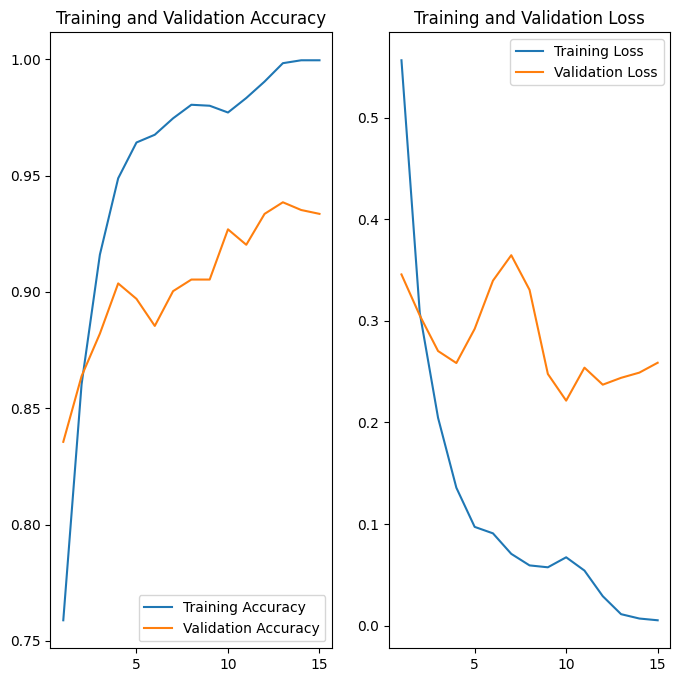

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(unflattened_X_test, y_test, verbose=2)

19/19 - 2s - 88ms/step - accuracy: 0.9336 - loss: 0.2586


### Cross validation

In [ ]:
model = tf.keras.Sequential([
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(256, activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])
model.compile(
  optimizer="adam",
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=6, verbose=1)
mc = tf.keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)
epochs = 15

history = model.fit(
  unflattened_X_train, y_train,
  validation_data=(unflattened_X_test, y_test), shuffle=True,
  epochs=epochs, batch_size=32
)

Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 48s 606ms/step - accuracy: 0.7025 - loss: 0.9980 - val_accuracy: 0.8571 - val_loss: 0.3067
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 83s 619ms/step - accuracy: 0.8881 - loss: 0.2543 - val_accuracy: 0.8970 - val_loss: 0.2495
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 81s 602ms/step - accuracy: 0.9371 - loss: 0.1698 - val_accuracy: 0.8953 - val_loss: 0.2579
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 83s 623ms/step - accuracy: 0.9594 - loss: 0.1220 - val_accuracy: 0.8987 - val_loss: 0.2474
Epoch 5/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 80s 603ms/step - accuracy: 0.9739 - loss: 0.0771 - val_accuracy: 0.9070 - val_loss: 0.2339
Epoch 6/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 83s 619ms/step - accuracy: 0.9913 - loss: 0.0545 - val_accuracy: 0.9120 - val_loss: 0.2524
Epoch 7/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 46s 608ms/step - accuracy: 0.9531 - loss: 0.1427 - val_accuracy: 0.9086 - val_loss: 0.2891
Epoch 8/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 49s 639ms/step - accuracy: 0.9786 - loss: 0.0573 - val_accu

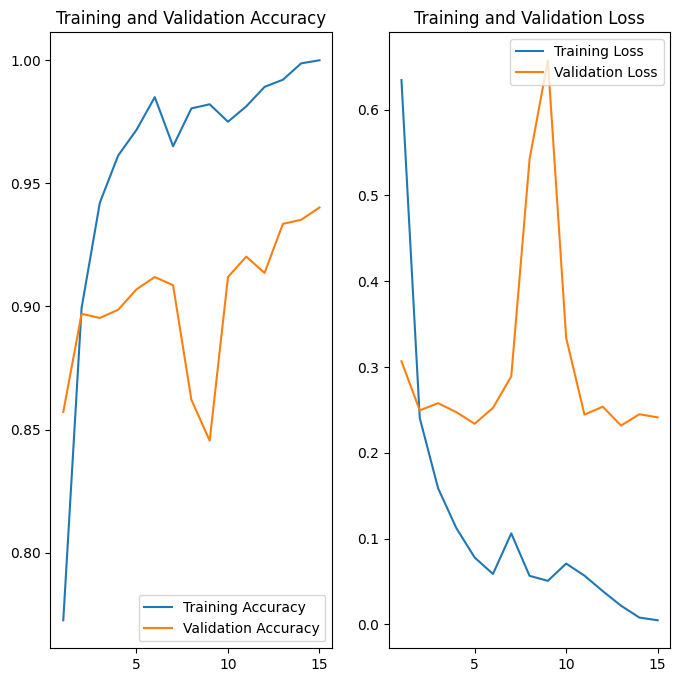

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(unflattened_X_test, y_test, verbose=2)

19/19 - 2s - 103ms/step - accuracy: 0.9402 - loss: 0.2413


# Greyscale images with HOG

In [ ]:
transformed_X_train = []
transformed_X_test = []

for img in X_train:
  img = np.reshape(img,(128, 128, 1))
  fd, img = hog(
    img,
    orientations=9,
    pixels_per_cell=(9, 9),
    cells_per_block=(2, 2),
    visualize=True,
    channel_axis=-1)
  img = img.reshape((img.shape[0] * img.shape[1]))
  transformed_X_train.append(img)

for img in X_test:
  img = np.reshape(img,(128, 128, 1))
  fd, img = hog(
    img,
    orientations=9,
    pixels_per_cell=(9, 9),
    cells_per_block=(2, 2),
    visualize=True,
    channel_axis=-1)
  img = img.reshape((img.shape[0] * img.shape[1]))
  transformed_X_test.append(img)

transformed_X_train = np.array(transformed_X_train)
transformed_X_test = np.array(transformed_X_test)

img = []

print(transformed_X_train.shape)
print(transformed_X_test.shape)

(2405, 16384)
(602, 16384)


## KNN hog

              precision    recall  f1-score   support

           0       0.86      0.94      0.90       304
           1       0.93      0.85      0.89       298

    accuracy                           0.89       602
   macro avg       0.90      0.89      0.89       602
weighted avg       0.90      0.89      0.89       602

Train score: 0.926403
Test score: 0.893688
Kappa score: 0.787157


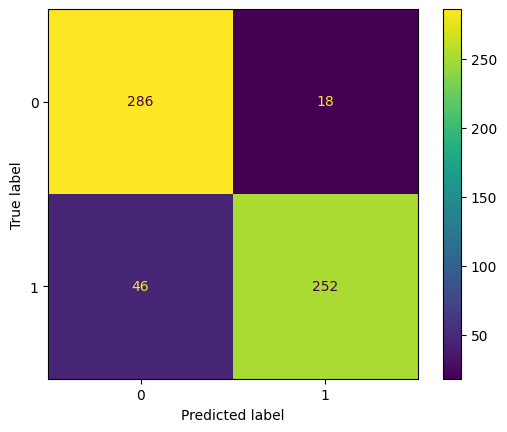

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here?
knn = KNeighborsClassifier(n_neighbors = 7)
knn.fit(transformed_X_train, y_train)

y_pred = knn.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % knn.score(transformed_X_train, y_train))
print("Test score: %f" % knn.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
grid_params = { 'n_neighbors' : [5,7,9,11,13,15],
               'weights' : ['uniform','distance'],
               'metric' : ['minkowski','euclidean','manhattan']}

gs = GridSearchCV(KNeighborsClassifier(), grid_params, verbose = 1, cv=3, n_jobs = -1)

g_res = gs.fit(transformed_X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
0.937216882886417
{'metric': 'manhattan', 'n_neighbors': 9, 'weights': 'distance'}


              precision    recall  f1-score   support

           0       0.94      0.96      0.95       304
           1       0.96      0.93      0.95       298

    accuracy                           0.95       602
   macro avg       0.95      0.95      0.95       602
weighted avg       0.95      0.95      0.95       602

Train score: 1.000000
Test score: 0.948505
Kappa score: 0.896969


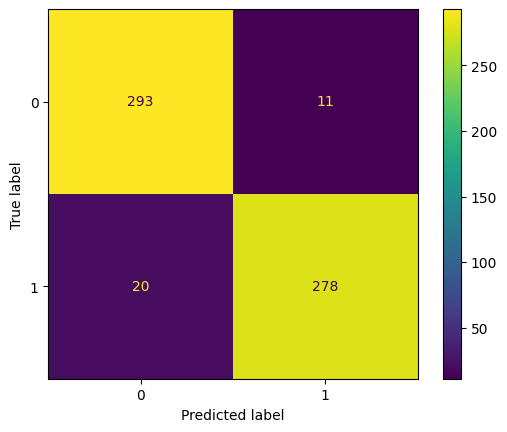

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here?
knn = KNeighborsClassifier(n_neighbors = 9, metric = 'manhattan', weights = 'distance')
knn.fit(transformed_X_train, y_train)

y_pred = knn.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % knn.score(transformed_X_train, y_train))
print("Test score: %f" % knn.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## Decision tree hog


              precision    recall  f1-score   support

           0       0.84      0.82      0.83       304
           1       0.82      0.85      0.83       298

    accuracy                           0.83       602
   macro avg       0.83      0.83      0.83       602
weighted avg       0.83      0.83      0.83       602

Train score: 1.000000
Test score: 0.830565


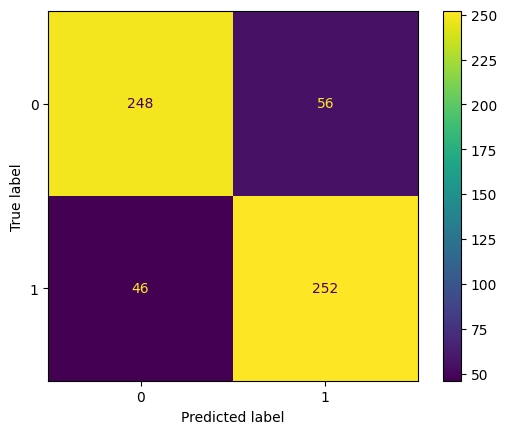

In [ ]:
# Terrible decision tree classifier - directly on pixel values
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import ExtraTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

dt = DecisionTreeClassifier(criterion='gini')
dt = dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)
report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

print("Train score: %f" % dt.score(X_train, y_train))
print("Test score: %f" % dt.score(X_test, y_test))

## Random forest hog


              precision    recall  f1-score   support

           0       0.88      0.99      0.93       304
           1       0.99      0.86      0.92       298

    accuracy                           0.93       602
   macro avg       0.93      0.93      0.93       602
weighted avg       0.93      0.93      0.93       602

Train score: 0.970062
Test score: 0.926910
Kappa score: 0.853622


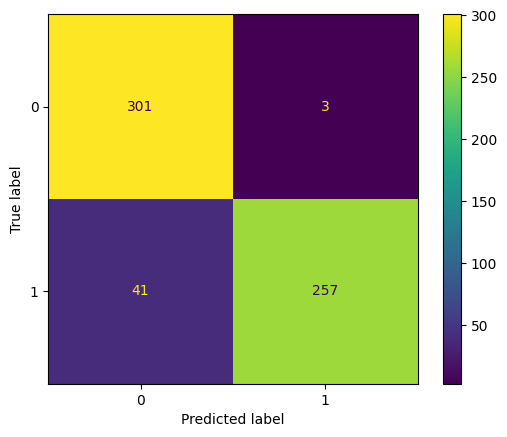

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(max_depth=7, random_state=0)

# Random forest classifier - directly on pixel values
RF = RF.fit(transformed_X_train, y_train)

y_pred = RF.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()
print("Train score: %f" % RF.score(transformed_X_train, y_train))
print("Test score: %f" % RF.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
from sklearn.ensemble import RandomForestClassifier

grid_params = {
    'max_features': ['sqrt'],
    'n_estimators': [10],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [12, 15, 20],
    'random_state': [0],
    'n_jobs' : [-1]
}

gs = GridSearchCV(RandomForestClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(transformed_X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 9 candidates, totalling 18 fits


/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


0.9097704297215917
{'criterion': 'gini', 'max_depth': 12, 'max_features': 'sqrt', 'n_estimators': 10, 'n_jobs': -1, 'random_state': 0}


              precision    recall  f1-score   support

           0       0.93      0.99      0.96       304
           1       0.99      0.92      0.95       298

    accuracy                           0.96       602
   macro avg       0.96      0.96      0.96       602
weighted avg       0.96      0.96      0.96       602

Train score: 1.000000
Test score: 0.956811
Kappa score: 0.913550


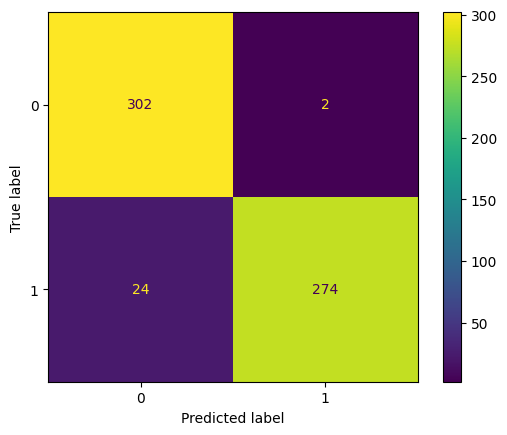

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(max_depth=15, criterion = 'entropy', random_state=0, n_jobs = -1, n_estimators = 250)

# Random forest classifier - directly on pixel values
RF = RF.fit(transformed_X_train, y_train)

y_pred = RF.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()
print("Train score: %f" % RF.score(transformed_X_train, y_train))
print("Test score: %f" % RF.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## SGDClassifier hog

              precision    recall  f1-score   support

           0       0.96      0.93      0.95       304
           1       0.93      0.96      0.95       298

    accuracy                           0.95       602
   macro avg       0.95      0.95      0.95       602
weighted avg       0.95      0.95      0.95       602

Train score: 1.000000
Test score: 0.948505
Kappa score: 0.897030


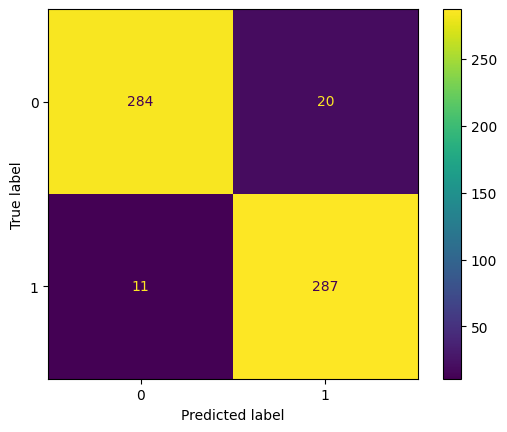

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(loss="modified_huber", max_iter=1000, eta0=1, learning_rate="constant", penalty=None)

# Train the model
sgd.fit(transformed_X_train, y_train)

# Make predictions
y_pred = sgd.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % sgd.score(transformed_X_train, y_train))
print("Test score: %f" % sgd.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
from sklearn.linear_model import SGDClassifier

grid_params = {
    'loss' : ["modified_huber"],
    'alpha' : [0.0001,0.001, 0.01, 0.1, 0.2],
    'learning_rate' : ["constant", "optimal"],
    'penalty' : ["l2", "l1", None],
    'n_jobs' : [-1]
}

gs = GridSearchCV(SGDClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(transformed_X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 30 candidates, totalling 60 fits


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py:540: FitFailedWarning: 
30 fits failed out of a total of 60.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
30 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/base.py", line 1473, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_stochastic_gradient.py", line 936, in fit
    self._more_validate_params()
  File "/usr/local/lib/python3.10

0.9422025219812367
{'alpha': 0.001, 'learning_rate': 'optimal', 'loss': 'modified_huber', 'n_jobs': -1, 'penalty': 'l2'}


              precision    recall  f1-score   support

           0       0.98      0.94      0.96       304
           1       0.94      0.98      0.96       298

    accuracy                           0.96       602
   macro avg       0.96      0.96      0.96       602
weighted avg       0.96      0.96      0.96       602

Train score: 1.000000
Test score: 0.960133
Kappa score: 0.920290


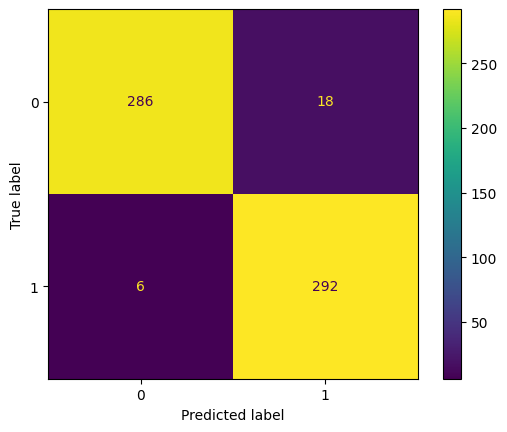

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(loss="modified_huber", max_iter=2000, eta0=1, learning_rate="optimal", penalty='l2', n_jobs = -1)

# Train the model
sgd.fit(transformed_X_train, y_train)

# Make predictions
y_pred = sgd.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % sgd.score(transformed_X_train, y_train))
print("Test score: %f" % sgd.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## MLP hog

              precision    recall  f1-score   support

           0       0.97      0.95      0.96       304
           1       0.95      0.97      0.96       298

    accuracy                           0.96       602
   macro avg       0.96      0.96      0.96       602
weighted avg       0.96      0.96      0.96       602

Train score: 1.000000
Test score: 0.961794
Kappa score: 0.923598


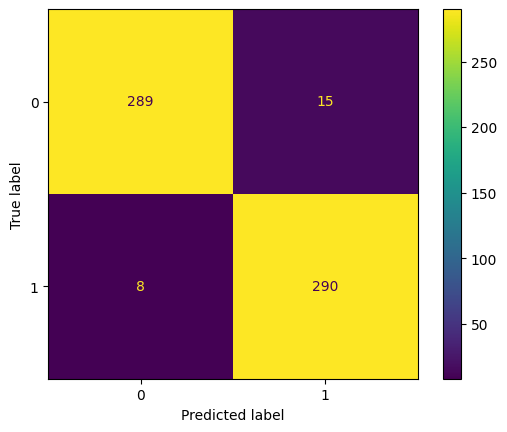

In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
clf = MLPClassifier(random_state=0, max_iter=2000, hidden_layer_sizes=(100,), activation='relu', solver='adam')
clf.fit(transformed_X_train, y_train)

# Make predictions
y_pred = clf.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % clf.score(transformed_X_train, y_train))
print("Test score: %f" % clf.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

### Cross validation

In [ ]:
grid_params = {
    'hidden_layer_sizes': [(50,50,50), (50,100,50), (100,)],
    'activation': ['tanh', 'relu'],
    'solver': ['sgd', 'adam'],
    'alpha': [0.0001, 0.05],
    'learning_rate': ['constant','adaptive'],
    'max_iter' : [2]
}

gs = GridSearchCV(MLPClassifier(), grid_params, verbose = 1, cv=2, n_jobs = -1)

g_res = gs.fit(X_train, y_train)

print(g_res.best_score_)
print(g_res.best_params_)

Fitting 2 folds for each of 48 candidates, totalling 96 fits
0.7168196397525322
{'activation': 'tanh', 'alpha': 0.05, 'hidden_layer_sizes': (50, 50, 50), 'learning_rate': 'constant', 'max_iter': 2, 'solver': 'sgd'}


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2) reached and the optimization hasn't converged yet.
  warnings.warn(


              precision    recall  f1-score   support

           0       0.97      0.96      0.97       304
           1       0.96      0.97      0.97       298

    accuracy                           0.97       602
   macro avg       0.97      0.97      0.97       602
weighted avg       0.97      0.97      0.97       602

Train score: 1.000000
Test score: 0.966777
Kappa score: 0.933557


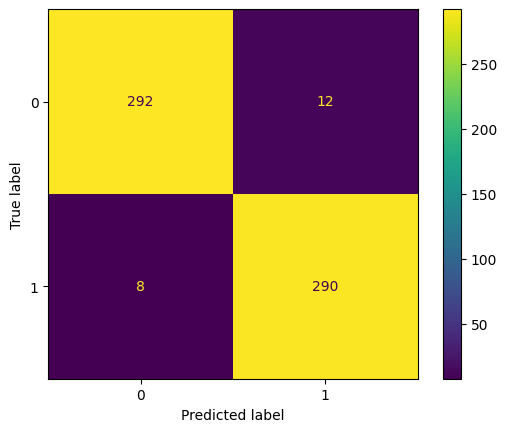

In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
clf = MLPClassifier(learning_rate = 'constant', max_iter=2000, hidden_layer_sizes=(50,50,50), activation='relu', solver='adam')
clf.fit(transformed_X_train, y_train)

# Make predictions
y_pred = clf.predict(transformed_X_test)

report = classification_report(y_test, y_pred)
print(report)
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

# Evaluate accuracy
print("Train score: %f" % clf.score(transformed_X_train, y_train))
print("Test score: %f" % clf.score(transformed_X_test, y_test))
print("Kappa score: %f" % cohen_kappa_score(y_test, y_pred))

## CNN hog

In [ ]:
model = tf.keras.Sequential([
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])

In [ ]:
model.compile(
  optimizer="adam",
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])

In [ ]:
epochs = 15

history = model.fit(
  transformed_X_train2, y_train,
  validation_data=(transformed_X_test2, y_test), shuffle=True,
  epochs=epochs, batch_size=32
)

Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 49s 630ms/step - accuracy: 0.7868 - loss: 2.2703 - val_accuracy: 0.9203 - val_loss: 0.2036
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 71s 484ms/step - accuracy: 0.9295 - loss: 0.1762 - val_accuracy: 0.9236 - val_loss: 0.2034
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 37s 490ms/step - accuracy: 0.9555 - loss: 0.1199 - val_accuracy: 0.9385 - val_loss: 0.1940
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 495ms/step - accuracy: 0.9763 - loss: 0.0720 - val_accuracy: 0.9385 - val_loss: 0.2161
Epoch 5/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 489ms/step - accuracy: 0.9755 - loss: 0.0654 - val_accuracy: 0.9452 - val_loss: 0.1839
Epoch 6/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 492ms/step - accuracy: 0.9905 - loss: 0.0291 - val_accuracy: 0.9369 - val_loss: 0.1995
Epoch 7/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 46s 563ms/step - accuracy: 0.9911 - loss: 0.0351 - val_accuracy: 0.9502 - val_loss: 0.1650
Epoch 8/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 78s 507ms/step - accuracy: 0.9942 - loss: 0.0273 - val_accu

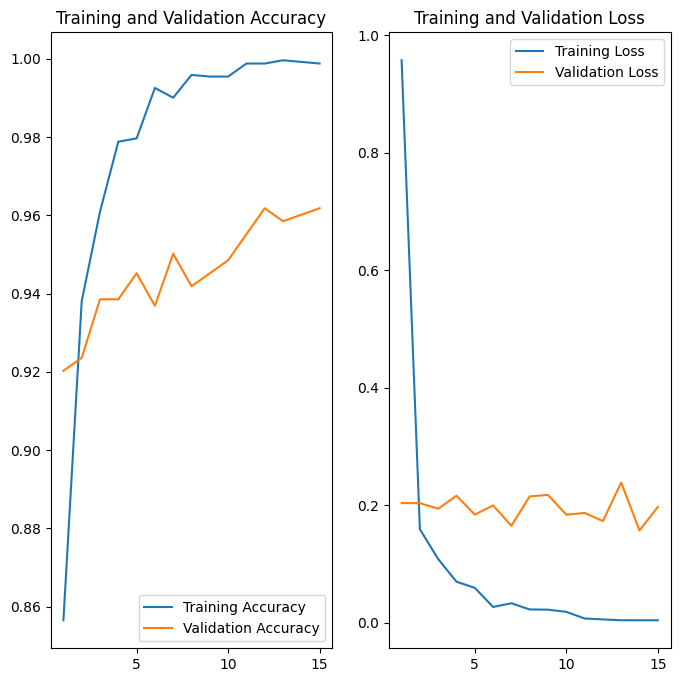

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(transformed_X_test2, y_test, verbose=2)

19/19 - 2s - 110ms/step - accuracy: 0.9618 - loss: 0.1969


In [ ]:
# Function to create model, required for KerasClassifier

def create_model(optimizer='adam'):
  # create model
  model = tf.keras.Sequential()
  model.add(tf.keras.layers.Conv2D(32, 5, activation='relu'))
  model.add(tf.keras.layers.MaxPooling2D())
  model.add(tf.keras.layers.Flatten())
  model.add(tf.keras.layers.Dense(128, activation='relu'))
  model.add(tf.keras.layers.Dense(1, activation='sigmoid'))

	# Compile mode
  model.compile(
  #optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
  optimizer=optimizer,
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])
  return model

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=6, verbose=1)
mc = tf.keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

# create model
model = KerasClassifier(model=create_model, verbose=0)

# define the grid search parameters
batch_size = [10, 20, 40, 60, 80, 100]
epochs = [15]
optimizer = ['SGD', 'RMSprop', 'Adagrad', 'Adadelta', 'Adam', 'Adamax', 'Nadam']
param_grid = dict(batch_size=batch_size, epochs=epochs, model__optimizer=optimizer)

grid = GridSearchCV(estimator=model, param_grid=param_grid, n_jobs=-1, cv=3)
grid_result = grid.fit(transformed_X_train, y_train)
# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

ValueError: 
All the 126 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.10/dist-packages/scikeras/wrappers.py", line 1501, in fit
    super().fit(X=X, y=y, sample_weight=sample_weight, **kwargs)
  File "/usr/local/lib/python3.10/dist-packages/scikeras/wrappers.py", line 770, in fit
    self._fit(
  File "/usr/local/lib/python3.10/dist-packages/scikeras/wrappers.py", line 936, in _fit
    self._check_model_compatibility(y)
  File "/usr/local/lib/python3.10/dist-packages/scikeras/wrappers.py", line 559, in _check_mode

## CNN hog modified

In [ ]:
# clear session
tf.keras.backend.clear_session(
    free_memory=True
)

In [ ]:
transformed_X_train2 = []
transformed_X_test2 = []

for img in transformed_X_train:
  img = np.reshape(img,(128, 128, 1))
  transformed_X_train2.append(img)

for img in transformed_X_test:
  img = np.reshape(img,(128, 128, 1))
  transformed_X_test2.append(img)

transformed_X_train2 = np.array(transformed_X_train2)
transformed_X_test2 = np.array(transformed_X_test2)

img = []

print(transformed_X_train2.shape)
print(transformed_X_test2.shape)

(2405, 128, 128, 1)
(602, 128, 128, 1)


In [ ]:
model = tf.keras.Sequential([
  tf.keras.layers.Conv2D(32, 5, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  tf.keras.layers.Flatten(),
  #tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(256, activation='relu'),
  tf.keras.layers.Dense(1,activation='sigmoid')
])
model.compile(
  optimizer="adam",
  loss=tf.keras.losses.BinaryCrossentropy(),
  metrics=['accuracy'])

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=6, verbose=1)
mc = tf.keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

epochs = 15

history = model.fit(
  transformed_X_train2, y_train,
  validation_data=(transformed_X_test2, y_test), shuffle=True,
  epochs=epochs, batch_size=32, callbacks = [es, mc]
)


Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 586ms/step - accuracy: 0.7822 - loss: 0.4226
Epoch 1: val_loss improved from inf to 0.14767, saving model to best_model.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 54s 688ms/step - accuracy: 0.7833 - loss: 0.4209 - val_accuracy: 0.9419 - val_loss: 0.1477
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 574ms/step - accuracy: 0.9549 - loss: 0.1262
Epoch 2: val_loss improved from 0.14767 to 0.12191, saving model to best_model.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 86s 747ms/step - accuracy: 0.9549 - loss: 0.1261 - val_accuracy: 0.9518 - val_loss: 0.1219
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 581ms/step - accuracy: 0.9680 - loss: 0.0916
Epoch 3: val_loss improved from 0.12191 to 0.09600, saving model to best_model.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 88s 829ms/step - accuracy: 0.9680 - loss: 0.0915 - val_accuracy: 0.9668 - val_loss: 0.0960
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 575ms/step - accuracy: 0.9780 - loss: 0.0605
Epoch 4: val_loss improved from 0.09600 to 0.08064,

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 124, 124, 32)        │             832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 62, 62, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 123008)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │      31,490,304 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 94,474,181 (360.39 MB)

 Trainable params: 31,491,393 (120.13 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 62,982,788 (240.26 MB)

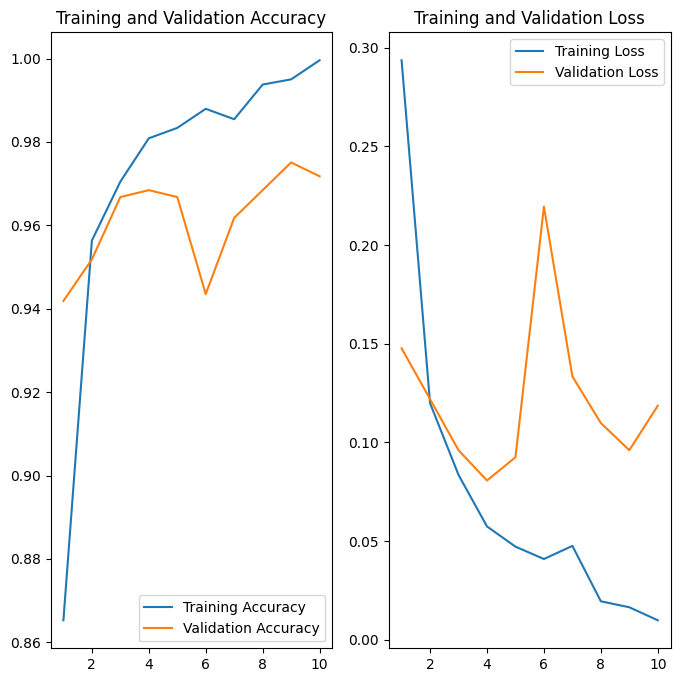

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(transformed_X_test2, y_test, verbose=2)

19/19 - 2s - 100ms/step - accuracy: 0.9718 - loss: 0.1186


# Own approach

In [ ]:
import os

os.environ["KERAS_BACKEND"] = "jax"  # @param ["tensorflow", "jax", "torch"]

import keras
from keras import layers
from keras import ops


import numpy as np
import matplotlib.pyplot as plt

In [ ]:
transformed_X_train = []
transformed_X_test = []

for img in X_train:
  img = np.reshape(img,(128, 128, 3))
  transformed_X_train.append(img)

for img in X_test:
  img = np.reshape(img,(128, 128, 3))
  transformed_X_test.append(img)

transformed_X_train = np.array(transformed_X_train)
transformed_X_test = np.array(transformed_X_test)

img = []

print(transformed_X_train.shape)
print(transformed_X_test.shape)

(2405, 128, 128, 3)
(602, 128, 128, 3)


In [ ]:
X_train = []
X_test = []

In [ ]:
num_classes = 2
input_shape = (128, 128, 3)

learning_rate = 0.001
weight_decay = 0.0001
batch_size = 50
num_epochs = 30  # For real training, use num_epochs=100. 10 is a test value
image_size = 128  # We'll resize input images to this size
patch_size = 8  # Size of the patches to be extract from the input images
num_patches = (image_size // patch_size) ** 2
projection_dim = 64
num_heads = 6
transformer_units = [
    projection_dim * 2,
    projection_dim,
]  # Size of the transformer layers
transformer_layers = 10
mlp_head_units = [
    256,
    128,
]  # Size of the dense layers of the final classifier


In [ ]:
data_augmentation = keras.Sequential(
    [
        layers.Normalization(),
        layers.RandomFlip("horizontal"),
    ],
    name="data_augmentation",
)
# Compute the mean and the variance of the training data for normalization.
data_augmentation.layers[0].adapt(transformed_X_train)


In [ ]:

def mlp(x, hidden_units, dropout_rate):
    for units in hidden_units:
        x = layers.Dense(units, activation=keras.activations.gelu)(x)
        x = layers.Dropout(dropout_rate)(x)
    return x


In [ ]:

class Patches(layers.Layer):
    def __init__(self, patch_size):
        super().__init__()
        self.patch_size = patch_size

    def call(self, images):
        input_shape = ops.shape(images)
        batch_size = input_shape[0]
        height = input_shape[1]
        width = input_shape[2]
        channels = input_shape[3]
        num_patches_h = height // self.patch_size
        num_patches_w = width // self.patch_size
        patches = keras.ops.image.extract_patches(images, size=self.patch_size)
        patches = ops.reshape(
            patches,
            (
                batch_size,
                num_patches_h * num_patches_w,
                self.patch_size * self.patch_size * channels,
            ),
        )
        return patches

    def get_config(self):
        config = super().get_config()
        config.update({"patch_size": self.patch_size})
        return config


In [ ]:
print(transformed_X_train[0])

[[[1.20852065 1.20556235 1.20172191]
  [1.20875764 1.20619249 1.20117271]
  [1.20861351 1.20710421 1.19891679]
  ...
  [1.19774044 1.20327377 1.19094479]
  [1.19864547 1.20417893 1.19185162]
  [1.19824243 1.20377564 1.19146872]]

 [[1.20939744 1.20643759 1.20260179]
  [1.20894301 1.20599782 1.2021178 ]
  [1.20876729 1.20591831 1.20179868]
  ...
  [1.19787276 1.20340598 1.19108391]
  [1.19854009 1.20407343 1.19202709]
  [1.19854164 1.20407486 1.19299734]]

 [[1.20903182 1.20607853 1.20222306]
  [1.20894802 1.20599461 1.20213938]
  [1.20908701 1.20616913 1.20225155]
  ...
  [1.19822574 1.20375896 1.19150019]
  [1.19819057 1.20372403 1.19363582]
  [1.19812524 1.20365834 1.19386375]]

 ...

 [[1.17795551 1.17924201 1.1732831 ]
  [1.17797256 1.1792593  1.17330039]
  [1.17789423 1.17918062 1.17322183]
  ...
  [1.17536843 1.17665493 1.17069602]
  [1.17554581 1.17683256 1.17087364]
  [1.17535901 1.17664576 1.17068684]]

 [[1.17802083 1.17930722 1.17334831]
  [1.17786086 1.1791476  1.17318869]


Image size: 128 X 128
Patch size: 8 X 8
Patches per image: 256
Elements per patch: 192


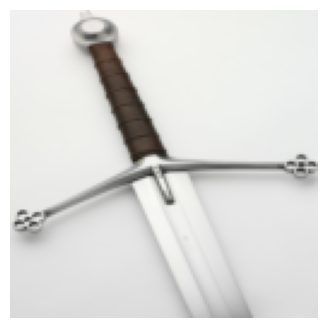

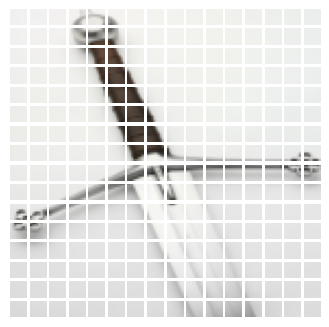

In [ ]:
plt.figure(figsize=(4, 4))
image = transformed_X_train[np.random.choice(range(transformed_X_train.shape[0]))]
plt.imshow(image)
plt.axis("off")

resized_image = ops.image.resize(
    ops.convert_to_tensor([image]), size=(image_size, image_size)
)
patches = Patches(patch_size)(resized_image)
print(f"Image size: {image_size} X {image_size}")
print(f"Patch size: {patch_size} X {patch_size}")
print(f"Patches per image: {patches.shape[1]}")
print(f"Elements per patch: {patches.shape[-1]}")

n = int(np.sqrt(patches.shape[1]))
plt.figure(figsize=(4, 4))
for i, patch in enumerate(patches[0]):
    ax = plt.subplot(n, n, i + 1)
    patch_img = ops.reshape(patch, (patch_size, patch_size, 3))
    plt.imshow(ops.convert_to_numpy(patch_img))
    plt.axis("off")

In [ ]:
class PatchEncoder(layers.Layer):
    def __init__(self, num_patches, projection_dim):
        super().__init__()
        self.num_patches = num_patches
        self.projection = layers.Dense(units=projection_dim)
        self.position_embedding = layers.Embedding(
            input_dim=num_patches, output_dim=projection_dim
        )

    def call(self, patch):
        positions = ops.expand_dims(
            ops.arange(start=0, stop=self.num_patches, step=1), axis=0
        )
        projected_patches = self.projection(patch)
        encoded = projected_patches + self.position_embedding(positions)
        return encoded

    def get_config(self):
        config = super().get_config()
        config.update({"num_patches": self.num_patches})
        return config


In [ ]:

def create_vit_classifier():
    inputs = keras.Input(shape=input_shape)
    # Augment data.
    augmented = data_augmentation(inputs)
    # Create patches.
    patches = Patches(patch_size)(augmented)
    # Encode patches.
    encoded_patches = PatchEncoder(num_patches, projection_dim)(patches)

    # Create multiple layers of the Transformer block.
    for _ in range(transformer_layers):
        # Layer normalization 1.
        x1 = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
        # Create a multi-head attention layer.
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=projection_dim, dropout=0.2
        )(x1, x1)
        # Skip connection 1.
        x2 = layers.Add()([attention_output, encoded_patches])
        # Layer normalization 2.
        x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
        # MLP.
        x3 = mlp(x3, hidden_units=transformer_units, dropout_rate=0.2)
        # Skip connection 2.
        encoded_patches = layers.Add()([x3, x2])

    # Create a [batch_size, projection_dim] tensor.
    representation = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
    representation = layers.Flatten()(representation)
    representation = layers.Dropout(0.5)(representation)
    # Add MLP.
    features = mlp(representation, hidden_units=mlp_head_units, dropout_rate=0.5)
    # Classify outputs.
    logits = layers.Dense(num_classes)(features)
    # Create the Keras model.
    model = keras.Model(inputs=inputs, outputs=logits)
    return model


Epoch 1/30
39/39 ━━━━━━━━━━━━━━━━━━━━ 134s 2s/step - accuracy: 0.6988 - loss: 1.5974 - top-5-accuracy: 1.0000 - val_accuracy: 0.9064 - val_loss: 0.8222 - val_top-5-accuracy: 1.0000
Epoch 2/30
39/39 ━━━━━━━━━━━━━━━━━━━━ 7s 183ms/step - accuracy: 0.8139 - loss: 1.0844 - top-5-accuracy: 1.0000 - val_accuracy: 0.9127 - val_loss: 0.2344 - val_top-5-accuracy: 1.0000
Epoch 3/30
39/39 ━━━━━━━━━━━━━━━━━━━━ 7s 175ms/step - accuracy: 0.8528 - loss: 0.5269 - top-5-accuracy: 1.0000 - val_accuracy: 0.9210 - val_loss: 0.1946 - val_top-5-accuracy: 1.0000
Epoch 4/30
39/39 ━━━━━━━━━━━━━━━━━━━━ 10s 178ms/step - accuracy: 0.8843 - loss: 0.3207 - top-5-accuracy: 1.0000 - val_accuracy: 0.9252 - val_loss: 0.1948 - val_top-5-accuracy: 1.0000
Epoch 5/30
39/39 ━━━━━━━━━━━━━━━━━━━━ 11s 185ms/step - accuracy: 0.8838 - loss: 0.3384 - top-5-accuracy: 1.0000 - val_accuracy: 0.9272 - val_loss: 0.2104 - val_top-5-accuracy: 1.0000
Epoch 6/30
39/39 ━━━━━━━━━━━━━━━━━━━━ 10s 168ms/step - accuracy: 0.8659 - loss: 0.2972 - 

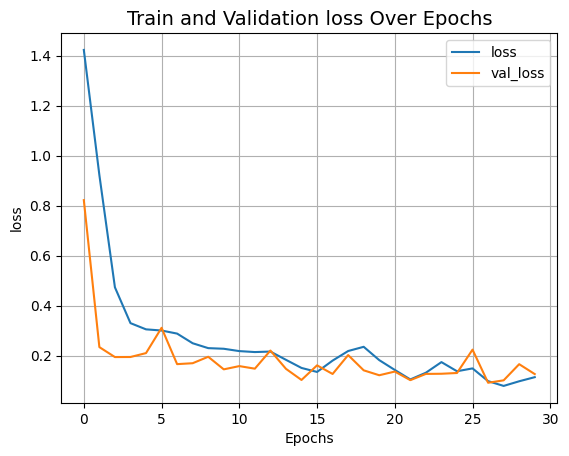

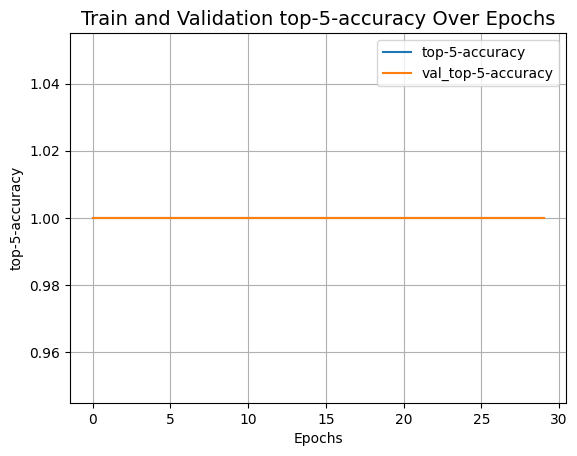

In [ ]:

def run_experiment(model):
    optimizer = keras.optimizers.AdamW(
        learning_rate=learning_rate, weight_decay=weight_decay
    )

    model.compile(
        optimizer=optimizer,
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[
            keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
            keras.metrics.SparseTopKCategoricalAccuracy(5, name="top-5-accuracy"),
        ],
    )

    checkpoint_filepath = "checkpoint.weights.h5"
    checkpoint_callback = keras.callbacks.ModelCheckpoint(
        checkpoint_filepath,
        monitor="val_accuracy",
        save_best_only=True,
        save_weights_only=True,
    )

    history = model.fit(
        x=transformed_X_train,
        y=y_train,
        batch_size=batch_size,
        epochs=num_epochs,
        validation_split=0.2,
        callbacks=[checkpoint_callback],
    )

    model.load_weights(checkpoint_filepath)
    _, accuracy, top_5_accuracy = model.evaluate(transformed_X_test, y_test)
    print(f"Test accuracy: {round(accuracy * 100, 2)}%")
    print(f"Test top 5 accuracy: {round(top_5_accuracy * 100, 2)}%")

    return history


vit_classifier = create_vit_classifier()
history = run_experiment(vit_classifier)


def plot_history(item):
    plt.plot(history.history[item], label=item)
    plt.plot(history.history["val_" + item], label="val_" + item)
    plt.xlabel("Epochs")
    plt.ylabel(item)
    plt.title("Train and Validation {} Over Epochs".format(item), fontsize=14)
    plt.legend()
    plt.grid()
    plt.show()


plot_history("loss")
plot_history("top-5-accuracy")


# Analysis

In [3]:
import pandas as pd

df = pd.DataFrame(columns=["knn Colour (HOG)","rf Grey (HOG)", "sgd Colour (HOG)","mlp Colour (HOG)",
                           "cnn Grey (HOG)","pre-trained Colour (Pixels)",
                           "ViT Colour (Pixels)"],
                  data=[[96.51,95.68,97.17,97.34,97.18,99.32,94.35]])

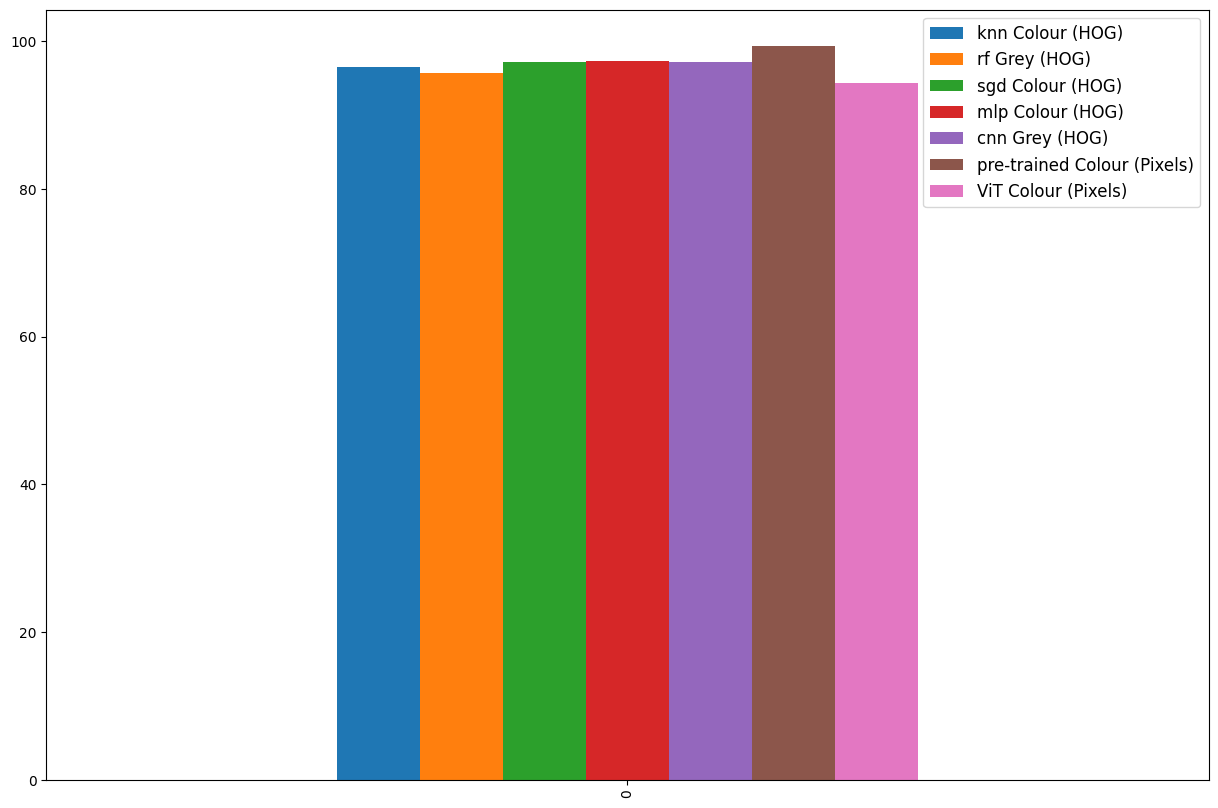

In [5]:
import matplotlib.pyplot as plt

df.plot.bar(figsize=(15,10))
plt.legend(fontsize = 12)

In [ ]:
df

,knn Colour (HOG),rf Grey (HOG),sgd Colour (HOG),mlp Colour (HOG),cnn Grey (HOG),pre-trained Colour (Pixels),ViT Colour (Pixels)
0,96.51,95.68,97.17,97.34,97.18,99.32,94.35
